# Parcial 2 — Computación Flexible
## Optimización Multiobjetivo de Sistemas Difusos Tipo Mamdani mediante Algoritmos Genéticos con PyGAD para el Control de un Servomotor de CD

---

## 1. Introducción y Fundamentos Teóricos

### 1.1. Sistemas de Inferencia Difusa Tipo Mamdani y Control Difuso
Los sistemas de inferencia difusa (FLS, *Fuzzy Logic Systems*) tipo Mamdani permiten diseñar leyes de control no lineales a partir de conocimiento expresado en reglas lingüísticas del tipo `IF antecedente THEN consecuente` (Jang et al., 1997; Nguyen et al., 2003). En un controlador difuso proporcional-derivativo (PD) de posición angular para un servomotor de corriente directa (CD), el controlador recibe en cada instante dos variables de entrada reales:
1. **Error de posición angular:**
   $$e(t) = r(t) - \theta(t) \in \left[-\frac{\pi}{2},\, \frac{\pi}{2}\right]\; [\text{rad}]$$
2. **Cambio (derivada temporal numérica) del error:**
   $$\Delta e(t) = \frac{de(t)}{dt} \approx \frac{e(t_k) - e(t_{k-1})}{\Delta t} \in \left[-\frac{\pi}{6},\, \frac{\pi}{6}\right]\; [\text{rad/s}]$$

y entrega como variable de salida el **voltaje de armadura** aplicado a las terminales del servomotor:
$$v(t) \in [-8.18,\, 8.18]\; [\text{V}]$$

En la arquitectura Mamdani Tipo-1 implementada mediante `scikit-fuzzy` (`skfuzzy` y `skfuzzy.control`), el proceso de inferencia consta de cuatro etapas:
1. **Fuzzificación:** Evaluación de los grados de pertenencia $\mu_{A_i}(e)$ y $\mu_{B_j}(\Delta e)$ sobre funciones de membresía triangulares (`skfuzzy.trimf`) definidas en sus respectivos universos de discurso fijos.
2. **Evaluación de reglas (conjunción e implicación):** Para cada regla activa $R_{ij}: \text{IF } e \text{ IS } A_i \text{ AND } \Delta e \text{ IS } B_j \text{ THEN } v \text{ IS } C_k$, se calcula la fuerza de disparo mediante la t-norma mínimo $\alpha_{ij} = \min(\mu_{A_i}(e), \mu_{B_j}(\Delta e))$ y se recorta el conjunto consecuente mediante implicación de Mamdani $\mu_{C_k'}(v) = \min(\alpha_{ij}, \mu_{C_k}(v))$.
3. **Agregación:** Combinación de todas las reglas activas mediante la s-norma máximo $\mu_{\text{agg}}(v) = \max_{(i,j)\in\mathcal{A}} \mu_{C_{k(i,j)}'}(v)$.
4. **Defuzzificación:** Obtención del voltaje escalar mediante el método del **centroide** (`skfuzzy.defuzz(..., 'centroid')`):
   $$v(t) = \frac{\int_{-8.18}^{8.18} v \cdot \mu_{\text{agg}}(v)\, dv}{\int_{-8.18}^{8.18} \mu_{\text{agg}}(v)\, dv}$$

### 1.2. Optimización Evolutiva mediante Algoritmos Genéticos (PyGAD) y Función Fitness Multiobjetivo
El ajuste manual de los centros, anchuras, solapamientos y base de reglas de un sistema difuso se vuelve intratable conforme crece el número de términos lingüísticos $N \in \{5, 7, 9\}$, pues el número de reglas crece cuadráticamente ($N^2 \in \{25, 49, 81\}$). Los **Algoritmos Genéticos (GA)** implementados en la biblioteca `pygad` permiten evolucionar una población de cromosomas candidatos mediante selección por torneo, cruza de dos puntos, mutación aleatoria acotada y elitismo.

Siguiendo la metodología de **Téllez-Velázquez et al. (2017)** (*"A Feasible Genetic Optimization Strategy for Parametric Interval Type-2 Fuzzy Logic Systems"*, *International Journal of Fuzzy Systems*, DOI `10.1007/s40815-017-0307-0`, Sección 5.1, Ecuaciones 12 y 13), la evaluación de cada individuo se realiza mediante la **Función de Aptitud Transitoria Multiobjetivo (MOTFF)** evaluada en las transiciones positiva ($-1 \to +1\text{ rad}$) y negativa ($+1 \to -1\text{ rad}$) de una onda cuadrada de período $100\text{ s}$ durante $T_{\text{sim}} = 200\text{ s}$ (descartando la transición inicial $0 \to +1\text{ rad}$ de los primeros $50\text{ s}$):

$$f_i = w_1 \frac{1}{1 + |OS_i^+|} + w_2 \frac{1}{1 + |SSE_i^+|} + w_3 \frac{t_r^0}{q^+ t_{r_i}^+} + w_4 \frac{t_s^0}{t_{s_i}^+} + w_5 \frac{1}{1 + |OS_i^-|} + w_6 \frac{1}{1 + |SSE_i^-|} + w_7 \frac{t_r^0}{q^- t_{r_i}^-} + w_8 \frac{t_s^0}{t_{s_i}^-} \quad (12)$$

con constantes obligatorias $t_r^0 = 9\text{ s}$, $t_s^0 = 13\text{ s}$, pesos equitativos $w_1 = \dots = w_8 = 0.125$ ($\sum_{k=1}^8 w_k = 1$), y el **factor de penalización obligatorio del tiempo de crecimiento (Ecuación 13)**:

$$q = \frac{\max(h^0) - \min(h_i)}{\max(h) - \min(h)} \quad (13)$$

que impide que el algoritmo genético premie falsos tiempos de subida en respuestas de amplitud incompleta.

## 2. Configuración del Entorno y Verificación de Versiones Obligatorias

In [1]:
import os
import sys
import time
import timeit
import json
import platform
import numpy as np
import scipy
from scipy.signal import lti, lsim, square
import skfuzzy as fuzz
from skfuzzy import control as ctrl
import pygad
import matplotlib
import matplotlib.pyplot as plt
from IPython.display import Image, Markdown, display

from src.config import (
    PLANT_NUM, PLANT_DEN, T_SIM, DT, X0, REF_PERIOD,
    ERROR_MIN, ERROR_MAX, DERROR_MIN, DERROR_MAX, VOLTAGE_MIN, VOLTAGE_MAX,
    TR0, TS0, FITNESS_WEIGHTS, EXPERIMENT_SEEDS, SOL_PER_POP, NUM_GENERATIONS
)
from src.plant_sim import create_plant, create_time_and_reference, ClosedLoopPlantSimulator
from src.chromosome import get_num_genes, get_gene_space, create_baseline_chromosome, decode_chromosome
from src.fuzzy_controller import MamdaniFuzzyController, measure_controller_memory_mb
from src.metrics_fitness import compute_penalty_factor_q, compute_step_metrics, evaluate_controller_response
from src.ga_optimizer import evaluate_baseline_controller, run_single_ga_experiment
from src.plotting_tables import summarize_experiments, generate_all_figures
from tests.test_verification import (
    test_plant_and_reference,
    test_equations_12_and_13,
    test_chromosome_encoding_and_repair,
    test_skfuzzy_equivalence,
)

print("=" * 72)
print("VERSIONES DEL ENTORNO DE EJECUCIÓN")
print("=" * 72)
print(f"Python       : {sys.version.split()[0]} ({platform.system()} {platform.release()})")
print(f"numpy        : {np.__version__}")
print(f"scipy        : {scipy.__version__}")
print(f"scikit-fuzzy : {fuzz.__version__}")
print(f"pygad        : {pygad.__version__}")
print(f"matplotlib   : {matplotlib.__version__}")
print("=" * 72)

VERSIONES DEL ENTORNO DE EJECUCIÓN
Python       : 3.14.2 (Windows 11)
numpy        : 2.4.2
scipy        : 1.18.1
scikit-fuzzy : 0.5.0
pygad        : 3.9.2
matplotlib   : 3.10.8


## 3. Metodología, Planta, Universos de Discurso y Codificación Genética

### 3.1. Planta del Sistema y Simulación Obligatoria con `scipy.signal.lsim`
La función de transferencia continua del servomotor de CD (Ecuación 10 del artículo de referencia y páginas 1, 2 y 12 de `Parcial 2.pdf`) es:
$$G(s) = \frac{0.5}{s^3 + 13.6667 s^2 + 23.3487 s}$$
Se construye mediante `G = lti([0.5], [1, 13.6667, 23.3487, 0])` y se simula en el intervalo exacto $t \in [0, 200]\text{ s}$ con paso $\Delta t = 0.05\text{ s}$ ($4,001$ muestras, $f_s = 20\text{ Hz}$), condiciones iniciales nulas `x0 = [0, 0, 0]`, sin ruido ni perturbaciones, invocando exclusivamente `tout, theta, xout = lsim(G, U=u, T=t, X0=x0)`.

### 3.2. Codificación Genética y Reparación de Cromosomas
Para cada configuración de $N \in \{5, 7, 9\}$ términos lingüísticos por variable (`error`, `derror`, `voltage`):
* **Genes de funciones de membresía ($9N$ genes):** Para cada una de las 3 variables se codifican $N$ centros $c_k \in [U_{\min}, U_{\max}]$ y $2N$ factores de anchura/solapamiento izquierdo y derecho $(w_{L,k}, w_{R,k}) \in [0.20, 1.80]$. El decodificador ordena los centros ($c_1 < c_2 < \dots < c_N$ con separación mínima no degenerada) y construye los triángulos $[a_k, c_k, b_k] \subseteq [U_{\min}, U_{\max}]$, evitando por construcción anchuras negativas, funciones invertidas o centros fuera de rango.
* **Genes de activación de reglas ($N^2$ genes):** Valores en $[0, 1]$ donde $g \ge 0.5 \implies 1$ (regla activa) y $g < 0.5 \implies 0$ (regla desactivada). Si todas las reglas se apagan, el mecanismo de reparación activa la regla central `(ZE, ZE) -> ZE` y aplica una penalización.
* **Genes de consecuentes de reglas ($N^2$ genes):** Índices en $[0, N-1]$ redondeados al entero más cercano que seleccionan el término lingüístico de voltaje para cada regla.
* **Longitud total del cromosoma:** $L(N) = 9N + 2N^2 \implies \mathbf{95\text{ genes}}$ ($N=5$), $\mathbf{161\text{ genes}}$ ($N=7$) y $\mathbf{243\text{ genes}}$ ($N=9$).

In [2]:
# Ejecución de las pruebas unitarias de verificación matemática y técnica
test_plant_and_reference()
test_equations_12_and_13()
test_chromosome_encoding_and_repair()
test_skfuzzy_equivalence()

G = create_plant()
t, r = create_time_and_reference()
print(f"Planta G(s) numerador: {G.num}, denominador: {G.den}")
print(f"Horizonte temporal: [{t[0]:.1f}, {t[-1]:.1f}] s con dt = {DT} s ({len(t)} muestras)")
for label_cfg, n_t in [("Controlador A", 5), ("Controlador B", 7), ("Controlador C", 9)]:
    print(f"{label_cfg} ({n_t} términos): {get_num_genes(n_t)} genes optimizables ({n_t**2} reglas posibles)")

[OK] test_plant_and_reference superado.
[OK] test_equations_12_and_13 superado.
[OK] test_chromosome_encoding_and_repair superado.


[OK] test_skfuzzy_equivalence superado (precisión < 1e-4 V).
Planta G(s) numerador: [0.5], denominador: [ 1.     13.6667 23.3487  0.    ]
Horizonte temporal: [0.0, 200.0] s con dt = 0.05 s (4001 muestras)
Controlador A (5 términos): 95 genes optimizables (25 reglas posibles)
Controlador B (7 términos): 161 genes optimizables (49 reglas posibles)
Controlador C (9 términos): 243 genes optimizables (81 reglas posibles)


## 4. Protocolo Experimental — Fase 1: Implementación y Evaluación de los Controladores Base (`automf`)
Antes de aplicar la optimización evolutiva, se evalúan los tres controladores iniciales generados con `automf` y con todas sus reglas activas ($25, 49$ y $81$ reglas).

Baseline 5 términos (25 reglas activas):
  Fitness = 0.6319 | q+ = 1.0350, q- = 1.0283
  OS+ = 0.0000, OS- = 0.0000 | SSE+ = 0.0424 rad, SSE- = 0.0401 rad
  tr+ = 30.55 s, tr- = 30.30 s | ts+ = 46.75 s, ts- = 46.03 s
  Tiempo inferencia = 10.629 ms | Memoria = 0.587 MB



Baseline 7 términos (49 reglas activas):
  Fitness = 0.6419 | q+ = 1.0291, q- = 1.0243
  OS+ = 0.0000, OS- = 0.0000 | SSE+ = 0.0396 rad, SSE- = 0.0366 rad
  tr+ = 28.10 s, tr- = 27.85 s | ts+ = 45.15 s, ts- = 44.18 s
  Tiempo inferencia = 25.468 ms | Memoria = 1.162 MB



Baseline 9 términos (81 reglas activas):
  Fitness = 0.6459 | q+ = 1.0284, q- = 1.0239
  OS+ = 0.0000, OS- = 0.0000 | SSE+ = 0.0393 rad, SSE- = 0.0361 rad
  tr+ = 27.05 s, tr- = 26.73 s | ts+ = 44.80 s, ts- = 43.78 s
  Tiempo inferencia = 53.103 ms | Memoria = 2.278 MB



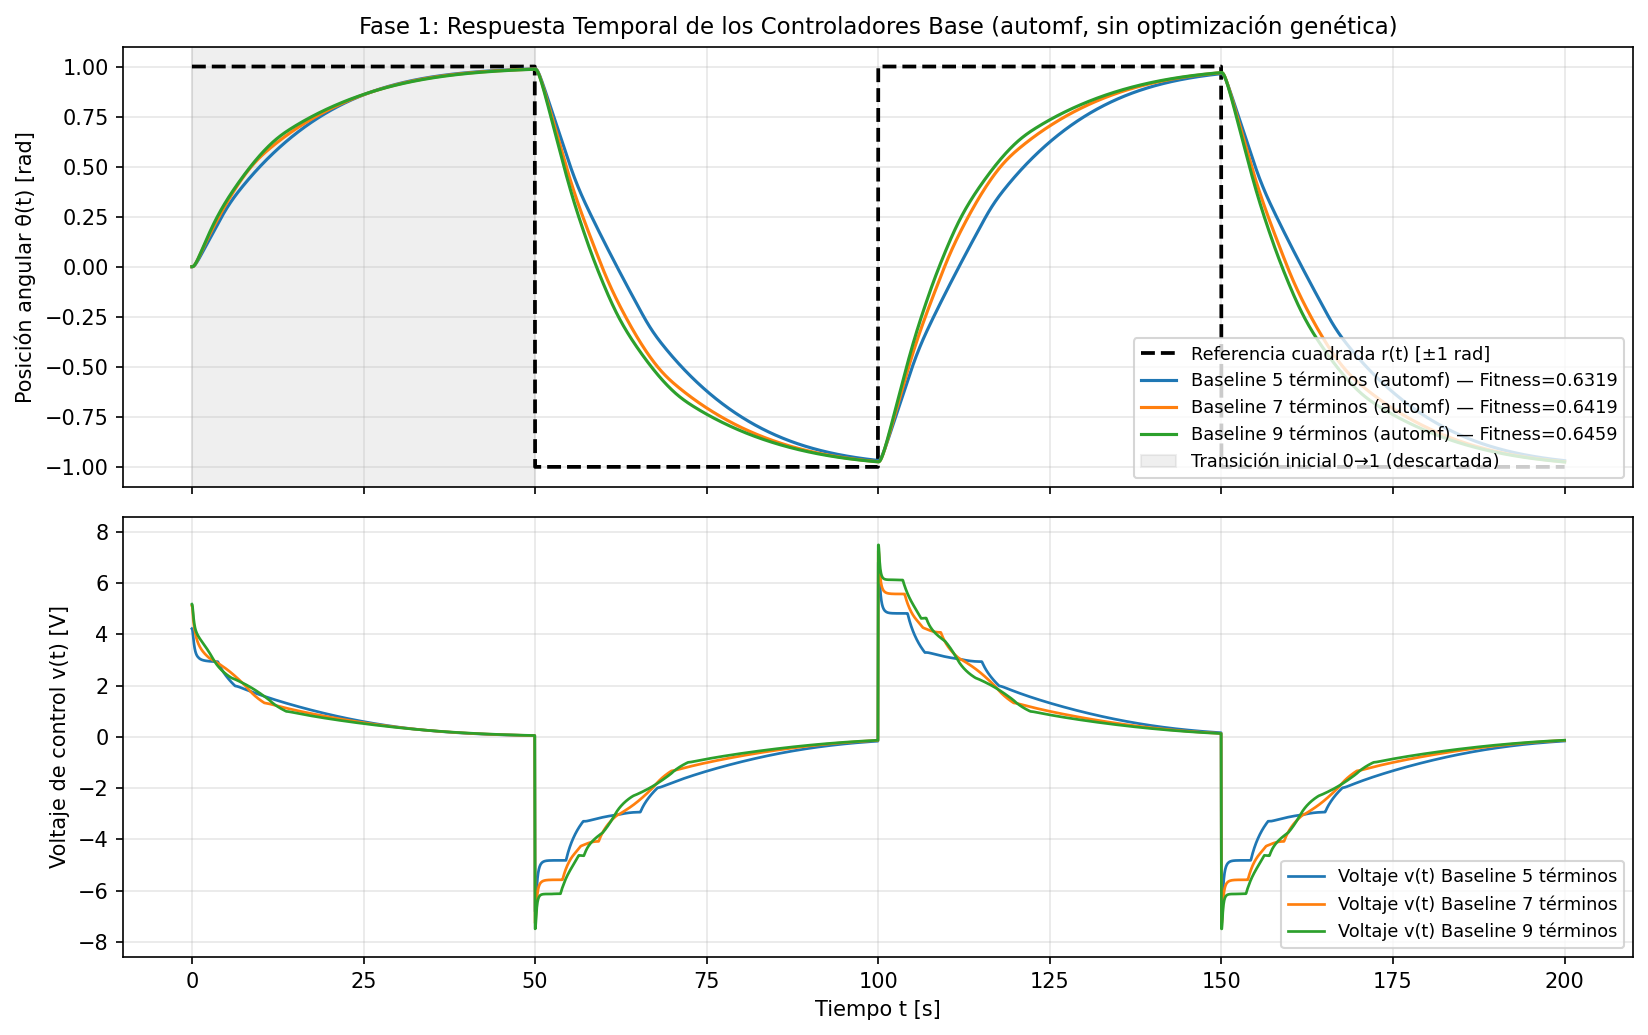

In [3]:
baselines = {}
for n_terms in [5, 7, 9]:
    baselines[n_terms] = evaluate_baseline_controller(n_terms)
    m = baselines[n_terms]["metrics"]
    print(
        f"Baseline {n_terms} términos ({baselines[n_terms]['num_active_rules']} reglas activas):\n"
        f"  Fitness = {m['fitness']:.4f} | q+ = {m['q_pos']:.4f}, q- = {m['q_neg']:.4f}\n"
        f"  OS+ = {m['OS_pos']:.4f}, OS- = {m['OS_neg']:.4f} | SSE+ = {m['SSE_pos']:.4f} rad, SSE- = {m['SSE_neg']:.4f} rad\n"
        f"  tr+ = {m['tr_pos']:.2f} s, tr- = {m['tr_neg']:.2f} s | ts+ = {m['ts_pos']:.2f} s, ts- = {m['ts_neg']:.2f} s\n"
        f"  Tiempo inferencia = {baselines[n_terms]['inference_time_ms']:.3f} ms | Memoria = {baselines[n_terms]['memory_mb']:.3f} MB\n"
    )

display(Image(filename="results/figures/fig1_baselines_response.png"))

## 5. Protocolo Experimental — Fases 2, 3, 4 y 5: Optimización con PyGAD, Selección, Costo Computacional y Repetibilidad (5 Semillas)
Se ejecutan (o cargan desde los archivos auditables en `results/runs/` generados por las corridas reales; cambie `FORCE_RERUN = True` si desea volver a correr las 15 optimizaciones desde cero) las **5 ejecuciones independientes** con semillas distintas `EXPERIMENT_SEEDS = [42, 100, 2026, 777, 999]` para cada configuración ($N \in \{5, 7, 9\}$), utilizando `sol_per_pop = 20` y `num_generations = 30`.

In [4]:
FORCE_RERUN = False  # Cambiar a True para re-ejecutar las 15 corridas completas (~4 min)

runs_by_terms = {5: [], 7: [], 9: []}
for n_terms in [5, 7, 9]:
    print(f"=== Resultados de las 5 ejecuciones independientes: Controlador de {n_terms} términos ===")
    for idx, seed in enumerate(EXPERIMENT_SEEDS, start=1):
        rec = run_single_ga_experiment(
            n_terms=n_terms,
            seed=seed,
            sol_per_pop=SOL_PER_POP,
            num_generations=NUM_GENERATIONS,
            force_rerun=FORCE_RERUN,
        )
        runs_by_terms[n_terms].append(rec)
        m = rec["metrics"]
        print(
            f"  Ejecución {idx}/5 (semilla={seed:4d}): Fitness={m['fitness']:.4f} | "
            f"OS+={m['OS_pos']:.4f}, OS-={m['OS_neg']:.4f} | "
            f"SSE+={m['SSE_pos']:.4f}, SSE-={m['SSE_neg']:.4f} | "
            f"tr+={m['tr_pos']:.2f}s, tr-={m['tr_neg']:.2f}s | "
            f"ts+={m['ts_pos']:.2f}s, ts-={m['ts_neg']:.2f}s | "
            f"Reglas={rec['num_active_rules']}/{rec['total_possible_rules']} | "
            f"Opt={rec['optimization_time_s']:.2f}s | Inf={rec['inference_time_ms']:.3f}ms | Mem={rec['memory_mb']:.3f}MB"
        )
    print()

summary = summarize_experiments(baselines, runs_by_terms)
figure_paths = generate_all_figures(baselines, runs_by_terms, summary)

=== Resultados de las 5 ejecuciones independientes: Controlador de 5 términos ===
  Ejecución 1/5 (semilla=  42): Fitness=0.8992 | OS+=0.0321, OS-=0.0000 | SSE+=0.0298, SSE-=0.0334 | tr+=10.05s, tr-=12.00s | ts+=13.30s, ts-=19.60s | Reglas=11/25 | Opt=16.62s | Inf=4.497ms | Mem=0.422MB
  Ejecución 2/5 (semilla= 100): Fitness=0.8212 | OS+=0.0009, OS-=0.0000 | SSE+=0.0118, SSE-=0.0097 | tr+=13.75s, tr-=12.60s | ts+=25.05s, ts-=18.45s | Reglas=17/25 | Opt=16.25s | Inf=6.269ms | Mem=0.483MB
  Ejecución 3/5 (semilla=2026): Fitness=0.7084 | OS+=0.0000, OS-=0.0195 | SSE+=0.0369, SSE-=0.0157 | tr+=22.10s, tr-=17.58s | ts+=38.25s, ts-=26.48s | Reglas=21/25 | Opt=15.99s | Inf=8.153ms | Mem=0.527MB
  Ejecución 4/5 (semilla= 777): Fitness=0.8504 | OS+=0.0000, OS-=0.0224 | SSE+=0.0209, SSE-=0.0207 | tr+=12.40s, tr-=14.45s | ts+=16.15s, ts-=17.95s | Reglas=18/25 | Opt=16.09s | Inf=6.734ms | Mem=0.493MB
  Ejecución 5/5 (semilla= 999): Fitness=0.8493 | OS+=0.0316, OS-=0.0151 | SSE+=0.0178, SSE-=0.0172

## 6. Resultados Experimentales y Tabla Obligatoria de Resultados

### Tabla Obligatoria de Resultados (`Parcial 2.pdf`, pág. 10)

| Métrica | 5 términos (Controlador A) | 7 términos (Controlador B) | 9 términos (Controlador C) |
| :--- | :---: | :---: | :---: |
| **Fitness promedio** (5 corridas) | 0.8257 ± 0.0713 | 0.7728 ± 0.0849 | 0.7678 ± 0.0472 |
| **Fitness máximo** (mejor corrida) | **0.8992** (semilla 42) | **0.8879** (semilla 42) | **0.8133** (semilla 777) |
| $OS^+$ (relativo) | 0.0321 (media: 0.0129 ± 0.0173) | 0.0124 (media: 0.0174 ± 0.0190) | 0.0216 (media: 0.0204 ± 0.0348) |
| $OS^-$ (relativo) | 0.0000 (media: 0.0114 ± 0.0107) | 0.0000 (media: 0.0065 ± 0.0145) | 0.0224 (media: 0.0201 ± 0.0196) |
| $SSE^+$ (rad) | 0.0298 (media: 0.0234 ± 0.0099) | 0.0115 (media: 0.0289 ± 0.0103) | 0.0163 (media: 0.0595 ± 0.0524) |
| $SSE^-$ (rad) | 0.0334 (media: 0.0193 ± 0.0088) | 0.0115 (media: 0.0319 ± 0.0124) | 0.0150 (media: 0.0545 ± 0.0436) |
| $t_r^+$ (s) | 10.05 (media: 14.10 ± 4.66) | 13.25 (media: 17.38 ± 6.88) | 17.40 (media: 19.25 ± 8.40) |
| $t_r^-$ (s) | 12.00 (media: 14.32 ± 2.20) | 10.85 (media: 16.90 ± 5.55) | 12.90 (media: 11.67 ± 2.65) |
| $t_s^+$ (s) | 13.30 (media: 21.60 ± 10.34) | 17.45 (media: 25.93 ± 10.09) | 21.90 (media: 31.86 ± 16.61) |
| $t_s^-$ (s) | 19.60 (media: 20.31 ± 3.50) | 14.70 (media: 27.05 ± 12.42) | 16.85 (media: 30.23 ± 18.22) |
| **Reglas activas** (mejor / media ± DE) | 11 / 25 (17.2 ± 3.8) | 36 / 49 (39.0 ± 4.7) | 45 / 81 (52.6 ± 7.7) |
| **Número de parámetros optimizados** | 95 genes | 161 genes | 243 genes |
| **Tiempo de optimización (s)** | 16.16 ± 0.30 s | 17.34 ± 0.05 s | 24.35 ± 0.25 s |
| **Tiempo promedio de inferencia (ms)** | 6.640 ± 1.401 ms | 18.372 ± 2.405 ms | 29.512 ± 4.944 ms |
| **Uso de memoria (MB)** | 0.486 ± 0.039 MB | 0.958 ± 0.083 MB | 1.407 ± 0.226 MB |

---

### 6.1. Listado Explícito de Reglas Activas de la Mejor Solución por Configuración

#### A) Mejor Controlador de 5 Términos (Semilla 42, Fitness = 0.8992, **11 / 25 reglas activas**):
1. `R01 (celda [1,1]): IF error IS NB AND derror IS NB THEN voltage IS NB`
2. `R03 (celda [1,3]): IF error IS NB AND derror IS ZE THEN voltage IS NB`
3. `R05 (celda [1,5]): IF error IS NB AND derror IS PB THEN voltage IS ZE`
4. `R09 (celda [2,4]): IF error IS NS AND derror IS PS THEN voltage IS NB`
5. `R15 (celda [3,5]): IF error IS ZE AND derror IS PB THEN voltage IS NS`
6. `R16 (celda [4,1]): IF error IS PS AND derror IS NB THEN voltage IS NS`
7. `R18 (celda [4,3]): IF error IS PS AND derror IS ZE THEN voltage IS PB`
8. `R20 (celda [4,5]): IF error IS PS AND derror IS PB THEN voltage IS PB`
9. `R22 (celda [5,2]): IF error IS PB AND derror IS NS THEN voltage IS ZE`
10. `R23 (celda [5,3]): IF error IS PB AND derror IS ZE THEN voltage IS PB`
11. `R24 (celda [5,4]): IF error IS PB AND derror IS PS THEN voltage IS PB`

#### B) Mejor Controlador de 7 Términos (Semilla 42, Fitness = 0.8879, **36 / 49 reglas activas**):
1. `R01 (celda [1,1]): IF error IS NB AND derror IS NB THEN voltage IS NB`
2. `R02 (celda [1,2]): IF error IS NB AND derror IS NM THEN voltage IS NB`
3. `R03 (celda [1,3]): IF error IS NB AND derror IS NS THEN voltage IS NB`
4. `R04 (celda [1,4]): IF error IS NB AND derror IS ZE THEN voltage IS NB`
5. `R06 (celda [1,6]): IF error IS NB AND derror IS PM THEN voltage IS NM`
6. `R07 (celda [1,7]): IF error IS NB AND derror IS PB THEN voltage IS ZE`
7. `R08 (celda [2,1]): IF error IS NM AND derror IS NB THEN voltage IS PS`
8. `R09 (celda [2,2]): IF error IS NM AND derror IS NM THEN voltage IS NB`
9. `R10 (celda [2,3]): IF error IS NM AND derror IS NS THEN voltage IS NB`
10. `R11 (celda [2,4]): IF error IS NM AND derror IS ZE THEN voltage IS NB`
11. `R12 (celda [2,5]): IF error IS NM AND derror IS PS THEN voltage IS NM`
12. `R13 (celda [2,6]): IF error IS NM AND derror IS PM THEN voltage IS PM`
13. `R15 (celda [3,1]): IF error IS NS AND derror IS NB THEN voltage IS PM`
14. `R17 (celda [3,3]): IF error IS NS AND derror IS NS THEN voltage IS NB`
15. `R18 (celda [3,4]): IF error IS NS AND derror IS ZE THEN voltage IS NM`
16. `R19 (celda [3,5]): IF error IS NS AND derror IS PS THEN voltage IS NS`
17. `R20 (celda [3,6]): IF error IS NS AND derror IS PM THEN voltage IS PS`
18. `R21 (celda [3,7]): IF error IS NS AND derror IS PB THEN voltage IS NM`
19. `R22 (celda [4,1]): IF error IS ZE AND derror IS NB THEN voltage IS NB`
20. `R25 (celda [4,4]): IF error IS ZE AND derror IS ZE THEN voltage IS ZE`
21. `R27 (celda [4,6]): IF error IS ZE AND derror IS PM THEN voltage IS PM`
22. `R30 (celda [5,2]): IF error IS PS AND derror IS NM THEN voltage IS NS`
23. `R31 (celda [5,3]): IF error IS PS AND derror IS NS THEN voltage IS PM`
24. `R32 (celda [5,4]): IF error IS PS AND derror IS ZE THEN voltage IS PM`
25. `R34 (celda [5,6]): IF error IS PS AND derror IS PM THEN voltage IS PB`
26. `R35 (celda [5,7]): IF error IS PS AND derror IS PB THEN voltage IS PB`
27. `R37 (celda [6,2]): IF error IS PM AND derror IS NM THEN voltage IS ZE`
28. `R39 (celda [6,4]): IF error IS PM AND derror IS ZE THEN voltage IS PM`
29. `R40 (celda [6,5]): IF error IS PM AND derror IS PS THEN voltage IS PM`
30. `R41 (celda [6,6]): IF error IS PM AND derror IS PM THEN voltage IS PB`
31. `R42 (celda [6,7]): IF error IS PM AND derror IS PB THEN voltage IS NB`
32. `R43 (celda [7,1]): IF error IS PB AND derror IS NB THEN voltage IS PS`
33. `R44 (celda [7,2]): IF error IS PB AND derror IS NM THEN voltage IS PS`
34. `R46 (celda [7,4]): IF error IS PB AND derror IS ZE THEN voltage IS PM`
35. `R47 (celda [7,5]): IF error IS PB AND derror IS PS THEN voltage IS PB`
36. `R48 (celda [7,6]): IF error IS PB AND derror IS PM THEN voltage IS PB`

#### C) Mejor Controlador de 9 Términos (Semilla 777, Fitness = 0.8133, **45 / 81 reglas activas**):
1. `R01 (celda [1,1]): IF error IS NVB AND derror IS NVB THEN voltage IS NVB`
2. `R05 (celda [1,5]): IF error IS NVB AND derror IS ZE THEN voltage IS NVB`
3. `R06 (celda [1,6]): IF error IS NVB AND derror IS PS THEN voltage IS NVB`
4. `R08 (celda [1,8]): IF error IS NVB AND derror IS PB THEN voltage IS NM`
5. `R09 (celda [1,9]): IF error IS NVB AND derror IS PVB THEN voltage IS ZE`
6. `R10 (celda [2,1]): IF error IS NB AND derror IS NVB THEN voltage IS NVB`
7. `R12 (celda [2,3]): IF error IS NB AND derror IS NM THEN voltage IS NVB`
8. `R13 (celda [2,4]): IF error IS NB AND derror IS NS THEN voltage IS PS`
9. `R14 (celda [2,5]): IF error IS NB AND derror IS ZE THEN voltage IS NB`
10. `R18 (celda [2,9]): IF error IS NB AND derror IS PVB THEN voltage IS NM`
11. `R20 (celda [3,2]): IF error IS NM AND derror IS NB THEN voltage IS ZE`
12. `R23 (celda [3,5]): IF error IS NM AND derror IS ZE THEN voltage IS ZE`
13. `R24 (celda [3,6]): IF error IS NM AND derror IS PS THEN voltage IS NM`
14. `R25 (celda [3,7]): IF error IS NM AND derror IS PM THEN voltage IS NM`
15. `R26 (celda [3,8]): IF error IS NM AND derror IS PB THEN voltage IS PVB`
16. `R28 (celda [4,1]): IF error IS NS AND derror IS NVB THEN voltage IS NVB`
17. `R29 (celda [4,2]): IF error IS NS AND derror IS NB THEN voltage IS NVB`
18. `R31 (celda [4,4]): IF error IS NS AND derror IS NS THEN voltage IS PS`
19. `R32 (celda [4,5]): IF error IS NS AND derror IS ZE THEN voltage IS NM`
20. `R34 (celda [4,7]): IF error IS NS AND derror IS PM THEN voltage IS PM`
21. `R36 (celda [4,9]): IF error IS NS AND derror IS PVB THEN voltage IS NB`
22. `R38 (celda [5,2]): IF error IS ZE AND derror IS NB THEN voltage IS NVB`
23. `R39 (celda [5,3]): IF error IS ZE AND derror IS NM THEN voltage IS NM`
24. `R46 (celda [6,1]): IF error IS PS AND derror IS NVB THEN voltage IS PM`
25. `R47 (celda [6,2]): IF error IS PS AND derror IS NB THEN voltage IS PM`
26. `R48 (celda [6,3]): IF error IS PS AND derror IS NM THEN voltage IS NS`
27. `R53 (celda [6,8]): IF error IS PS AND derror IS PB THEN voltage IS PVB`
28. `R54 (celda [6,9]): IF error IS PS AND derror IS PVB THEN voltage IS PM`
29. `R57 (celda [7,3]): IF error IS PM AND derror IS NM THEN voltage IS ZE`
30. `R59 (celda [7,5]): IF error IS PM AND derror IS ZE THEN voltage IS PM`
31. `R60 (celda [7,6]): IF error IS PM AND derror IS PS THEN voltage IS PVB`
32. `R62 (celda [7,8]): IF error IS PM AND derror IS PB THEN voltage IS NM`
33. `R63 (celda [7,9]): IF error IS PM AND derror IS PVB THEN voltage IS PVB`
34. `R64 (celda [8,1]): IF error IS PB AND derror IS NVB THEN voltage IS NB`
35. `R65 (celda [8,2]): IF error IS PB AND derror IS NB THEN voltage IS ZE`
36. `R66 (celda [8,3]): IF error IS PB AND derror IS NM THEN voltage IS NB`
37. `R68 (celda [8,5]): IF error IS PB AND derror IS ZE THEN voltage IS PB`
38. `R70 (celda [8,7]): IF error IS PB AND derror IS PM THEN voltage IS PB`
39. `R71 (celda [8,8]): IF error IS PB AND derror IS PB THEN voltage IS PVB`
40. `R72 (celda [8,9]): IF error IS PB AND derror IS PVB THEN voltage IS PVB`
41. `R75 (celda [9,3]): IF error IS PVB AND derror IS NM THEN voltage IS NM`
42. `R76 (celda [9,4]): IF error IS PVB AND derror IS NS THEN voltage IS PVB`
43. `R77 (celda [9,5]): IF error IS PVB AND derror IS ZE THEN voltage IS PM`
44. `R78 (celda [9,6]): IF error IS PVB AND derror IS PS THEN voltage IS PVB`
45. `R81 (celda [9,9]): IF error IS PVB AND derror IS PVB THEN voltage IS NB`

## 7. Gráficas de Respuesta Temporal, Convergencia, Funciones de Membresía, Reglas Activas y Costo Computacional

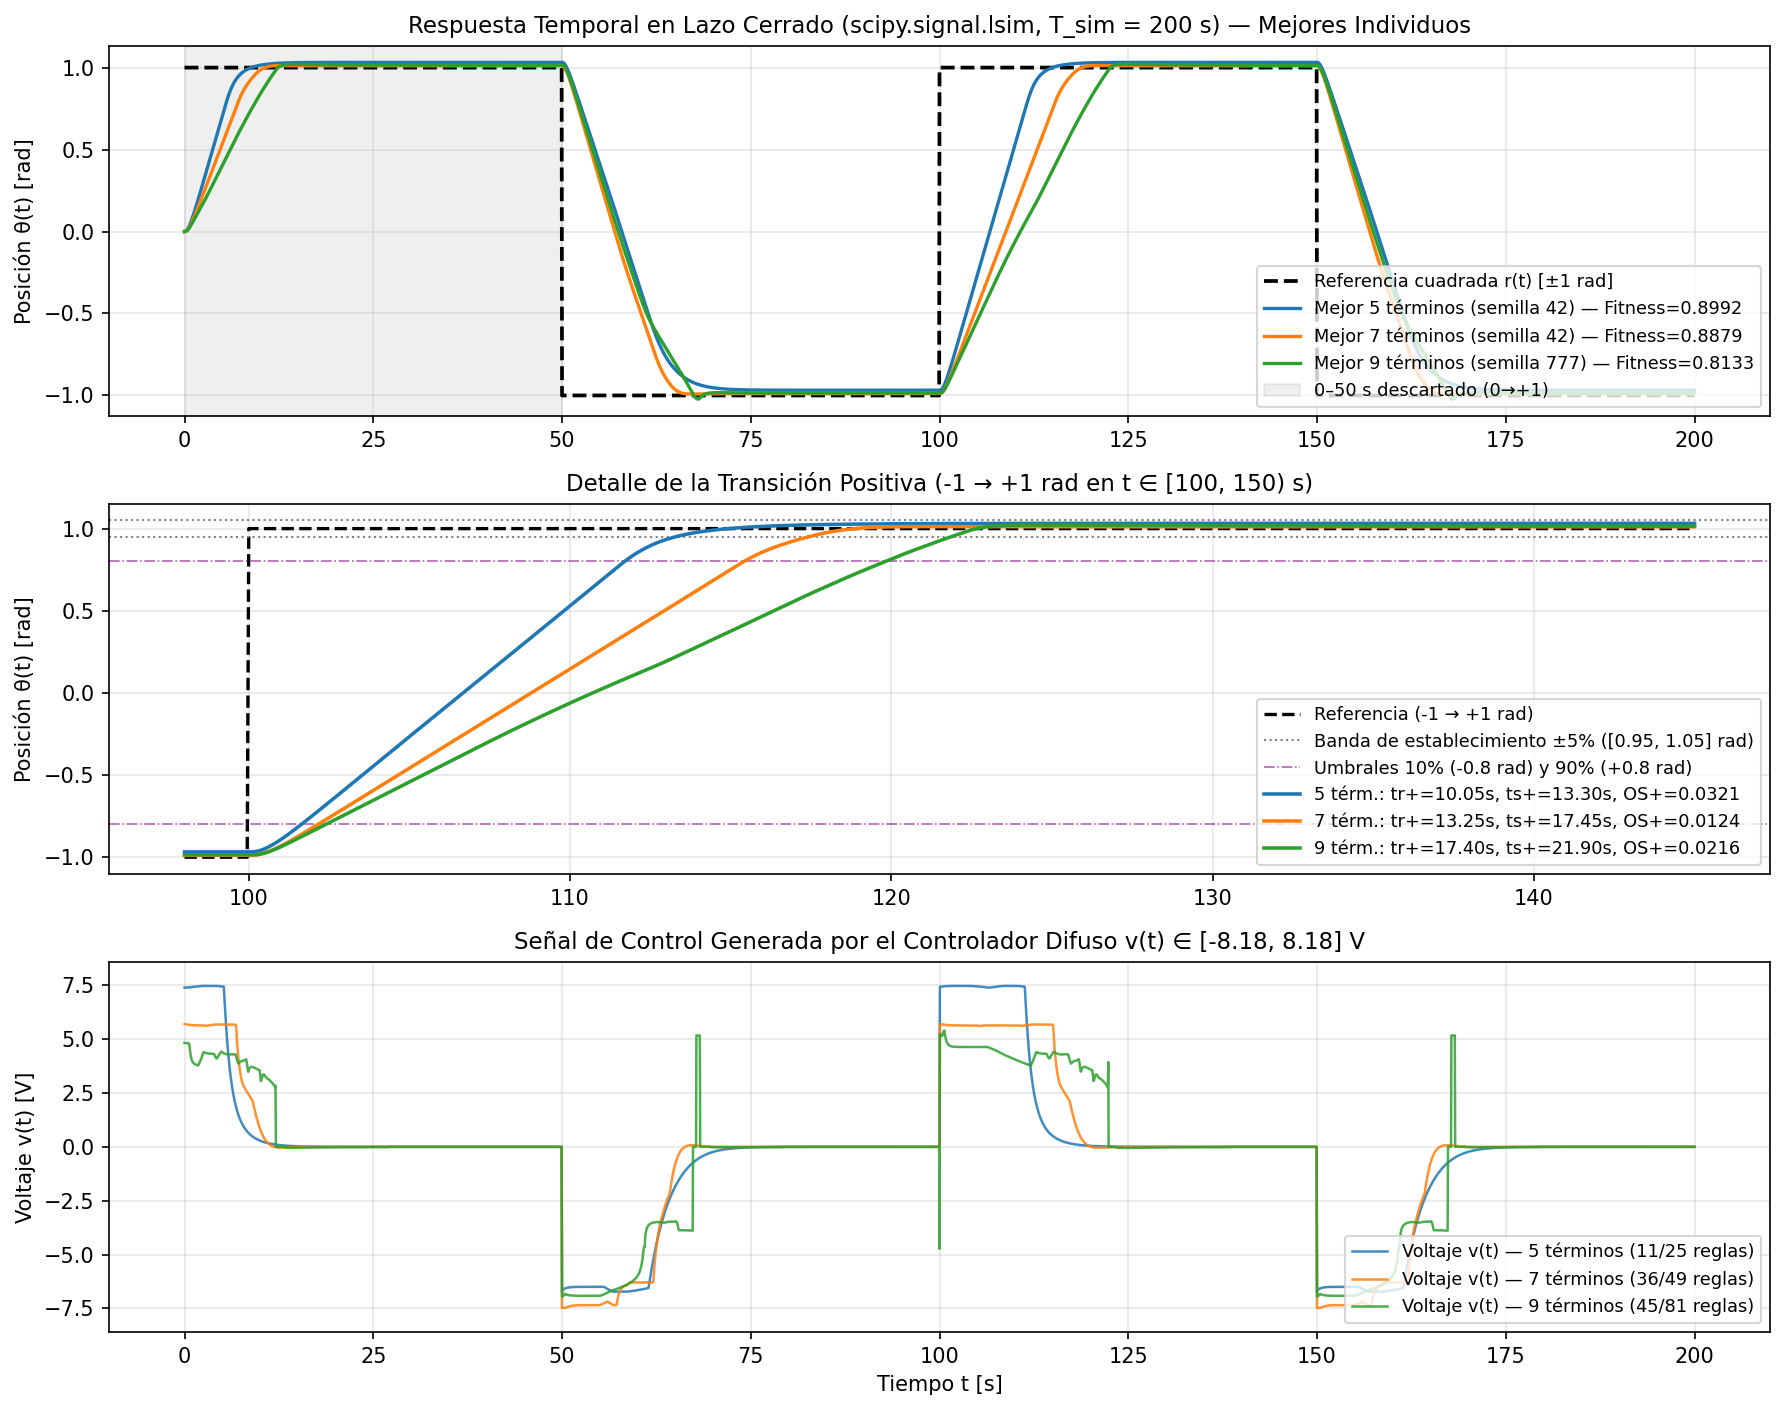

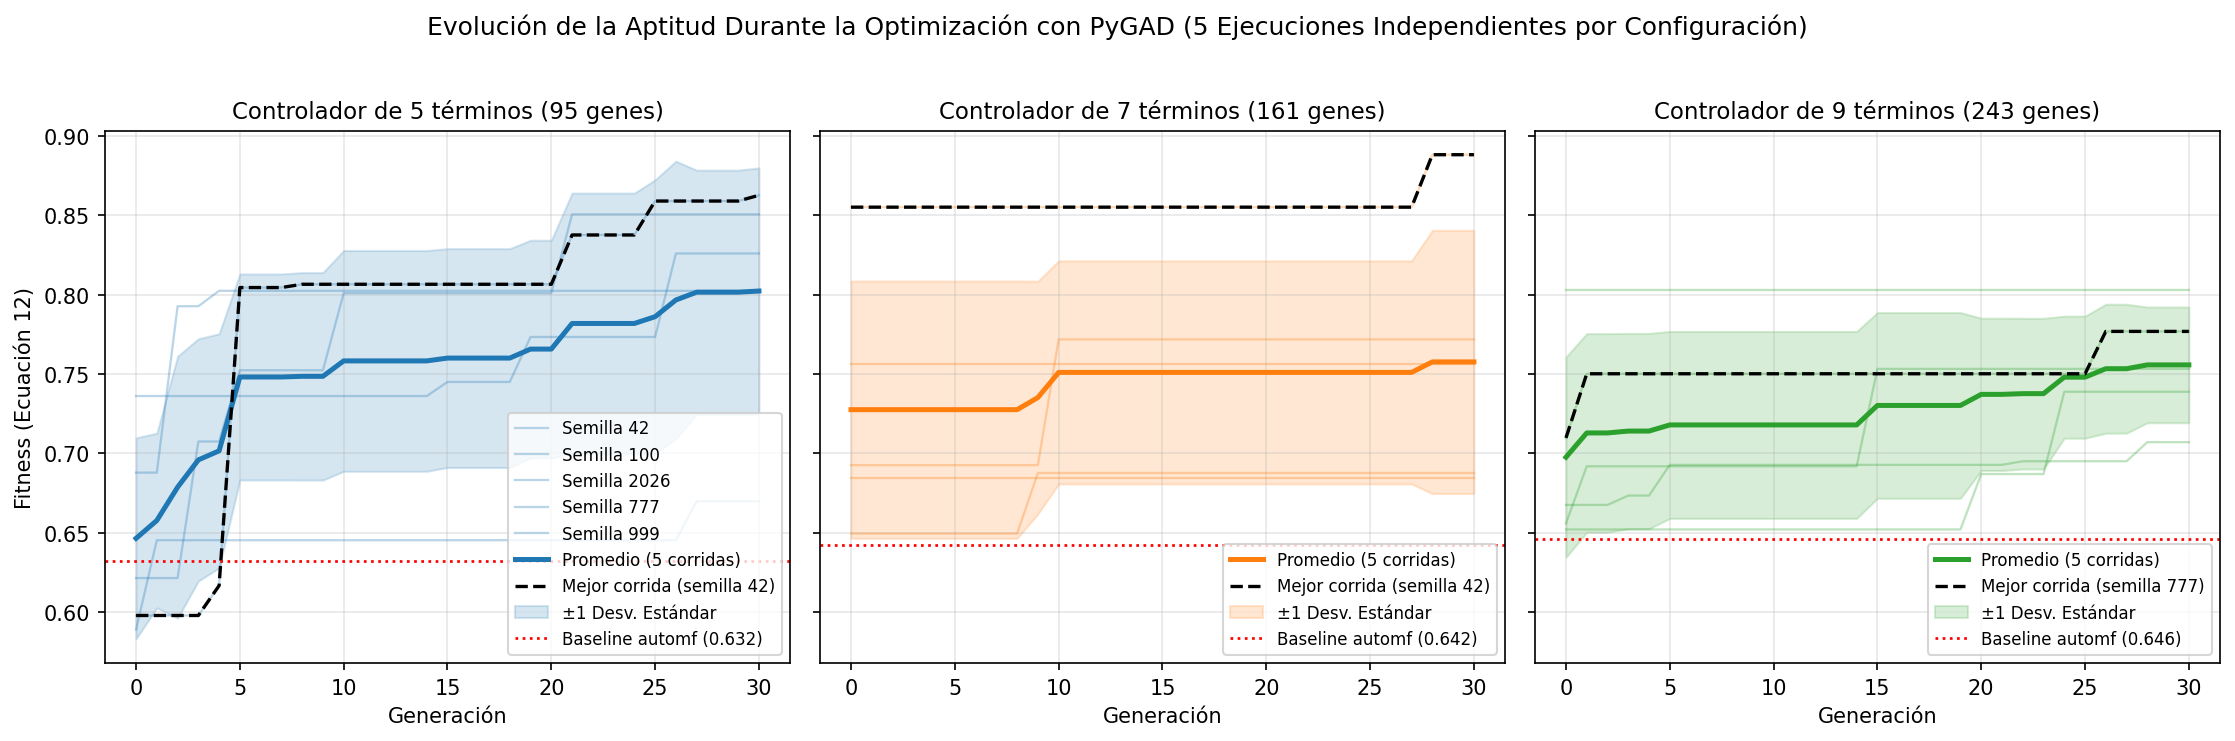

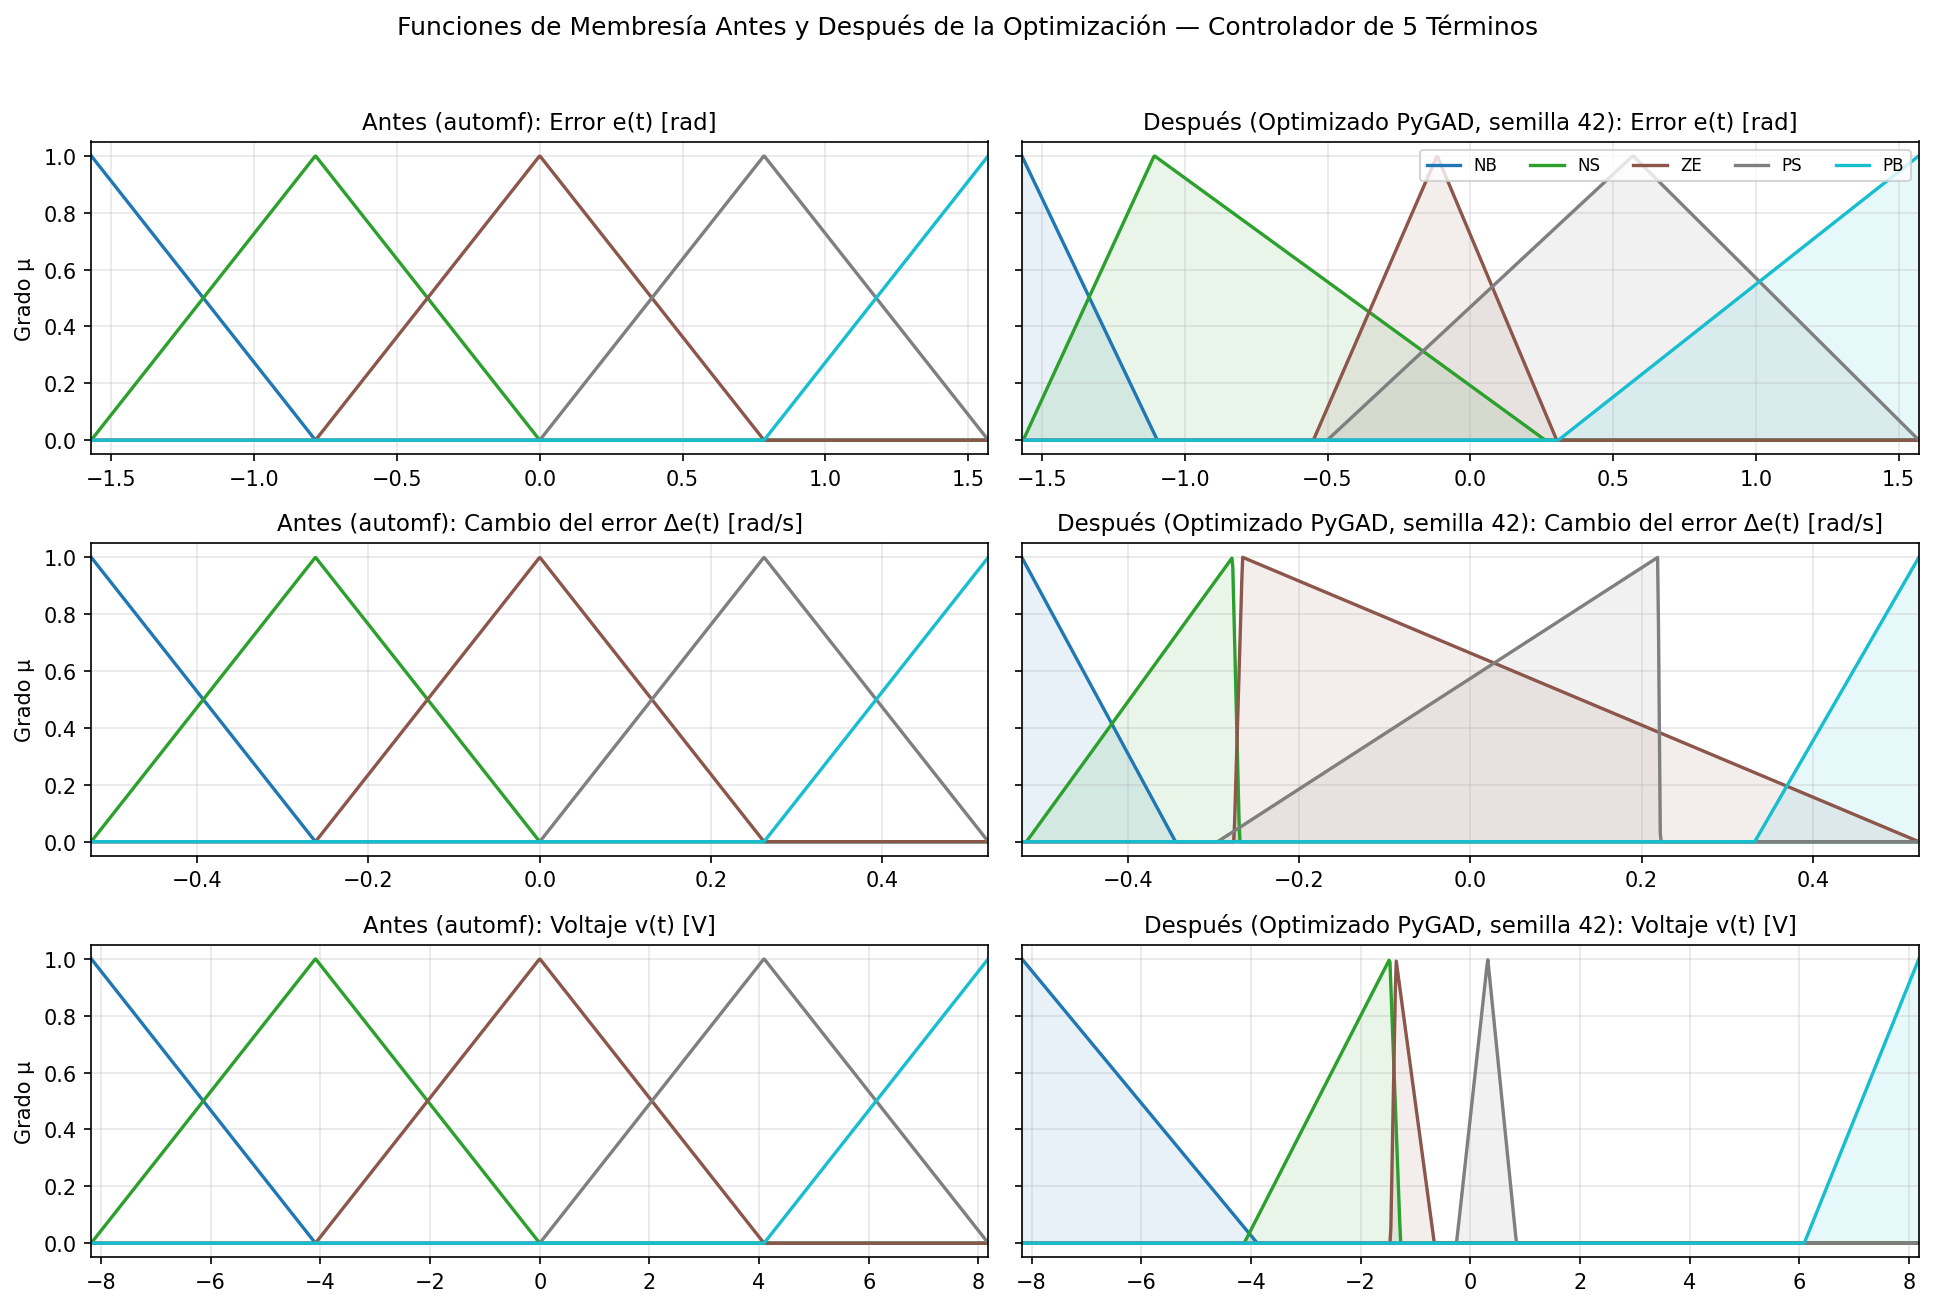

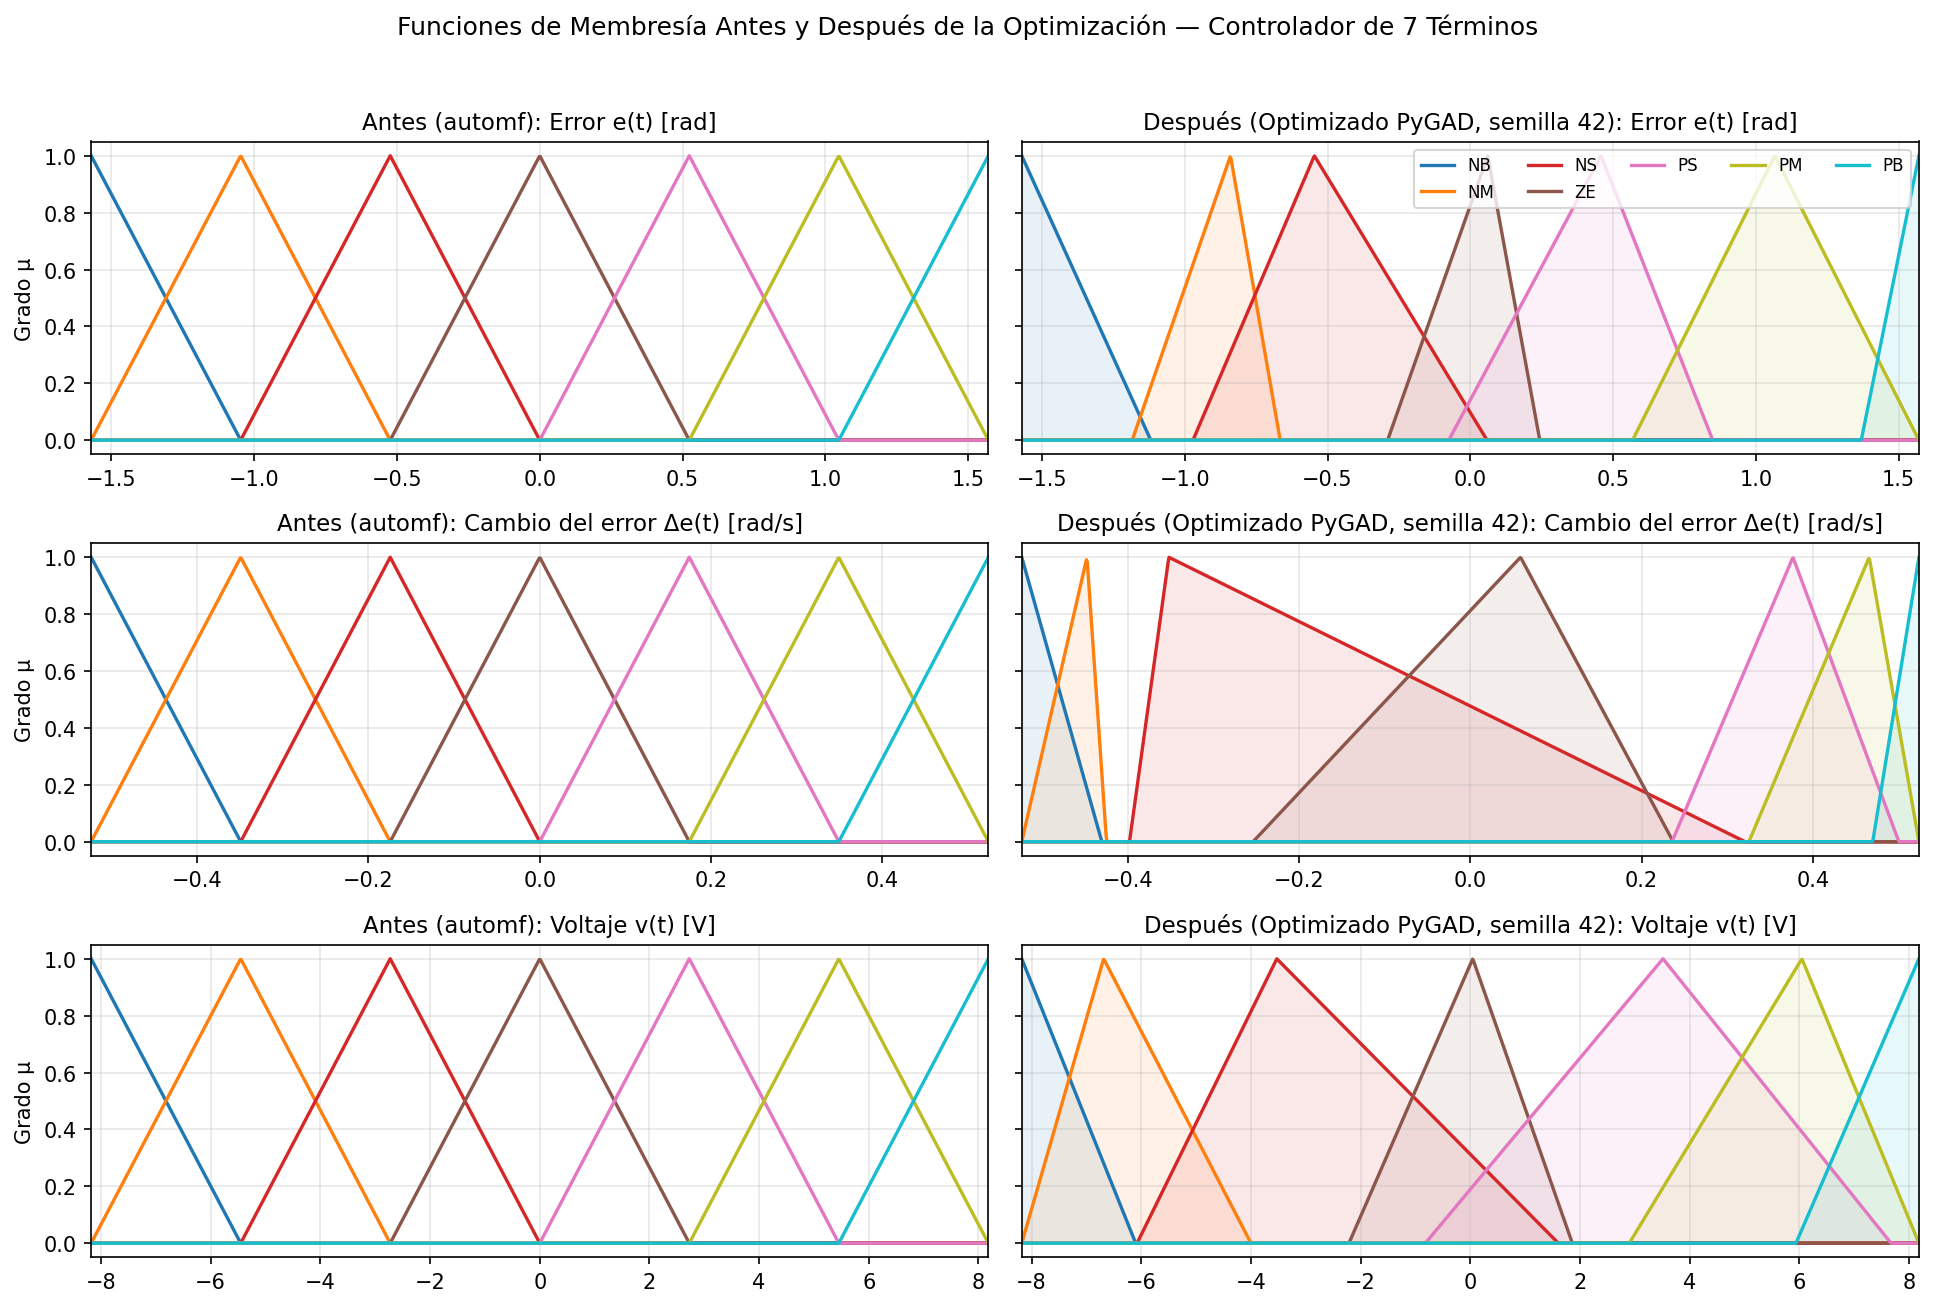

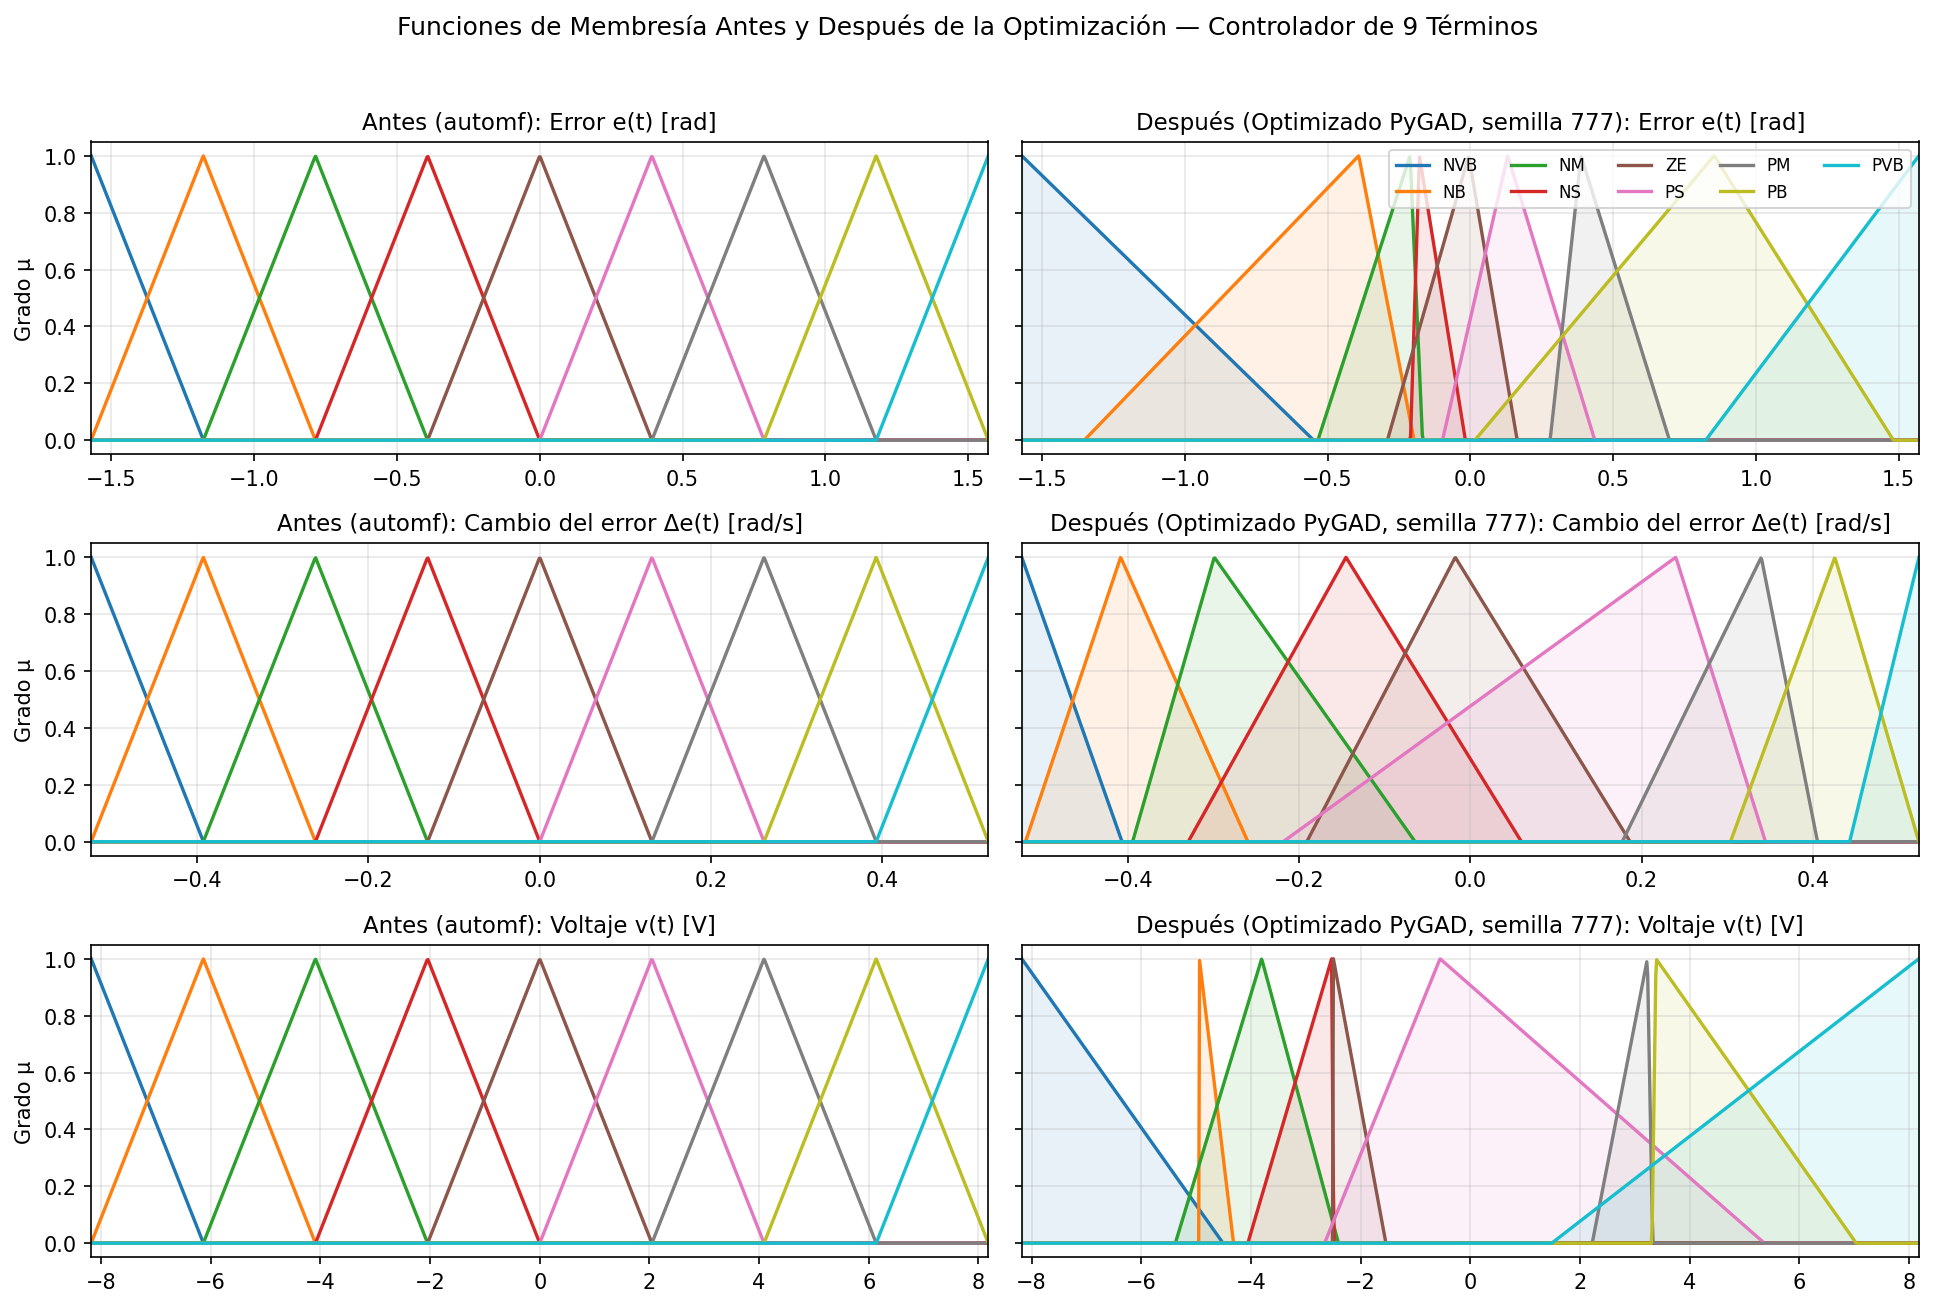

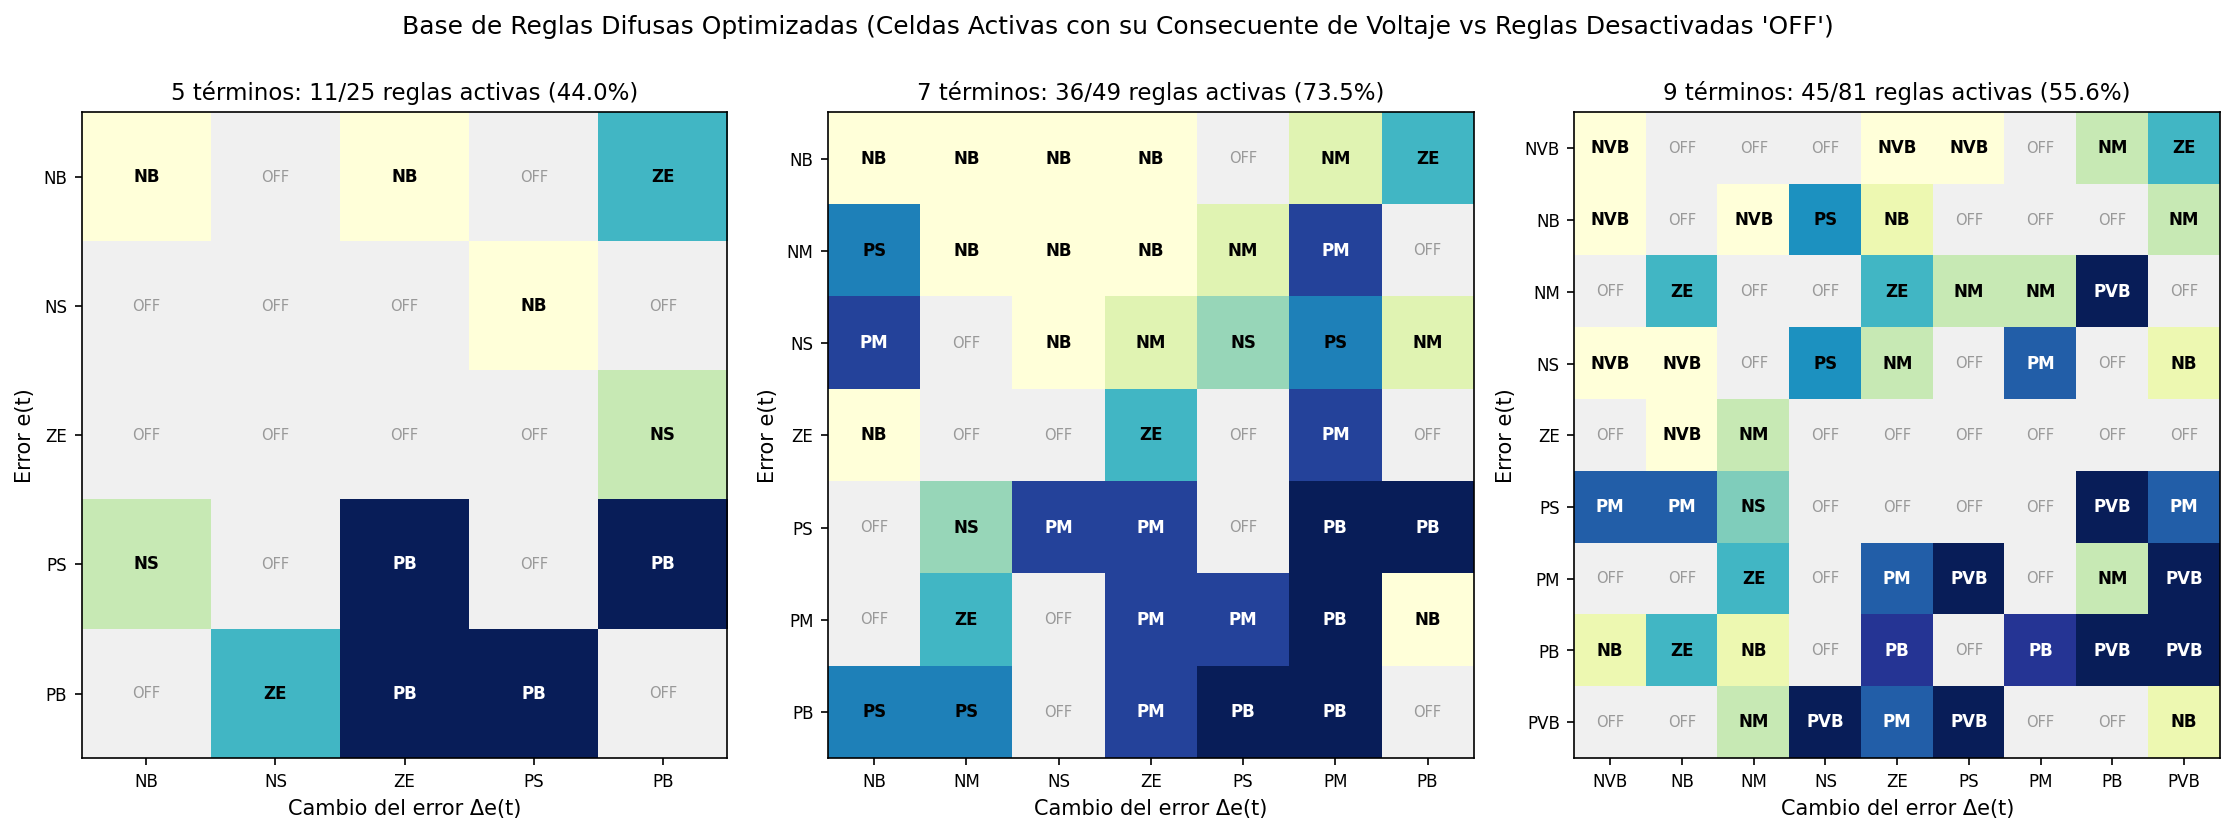

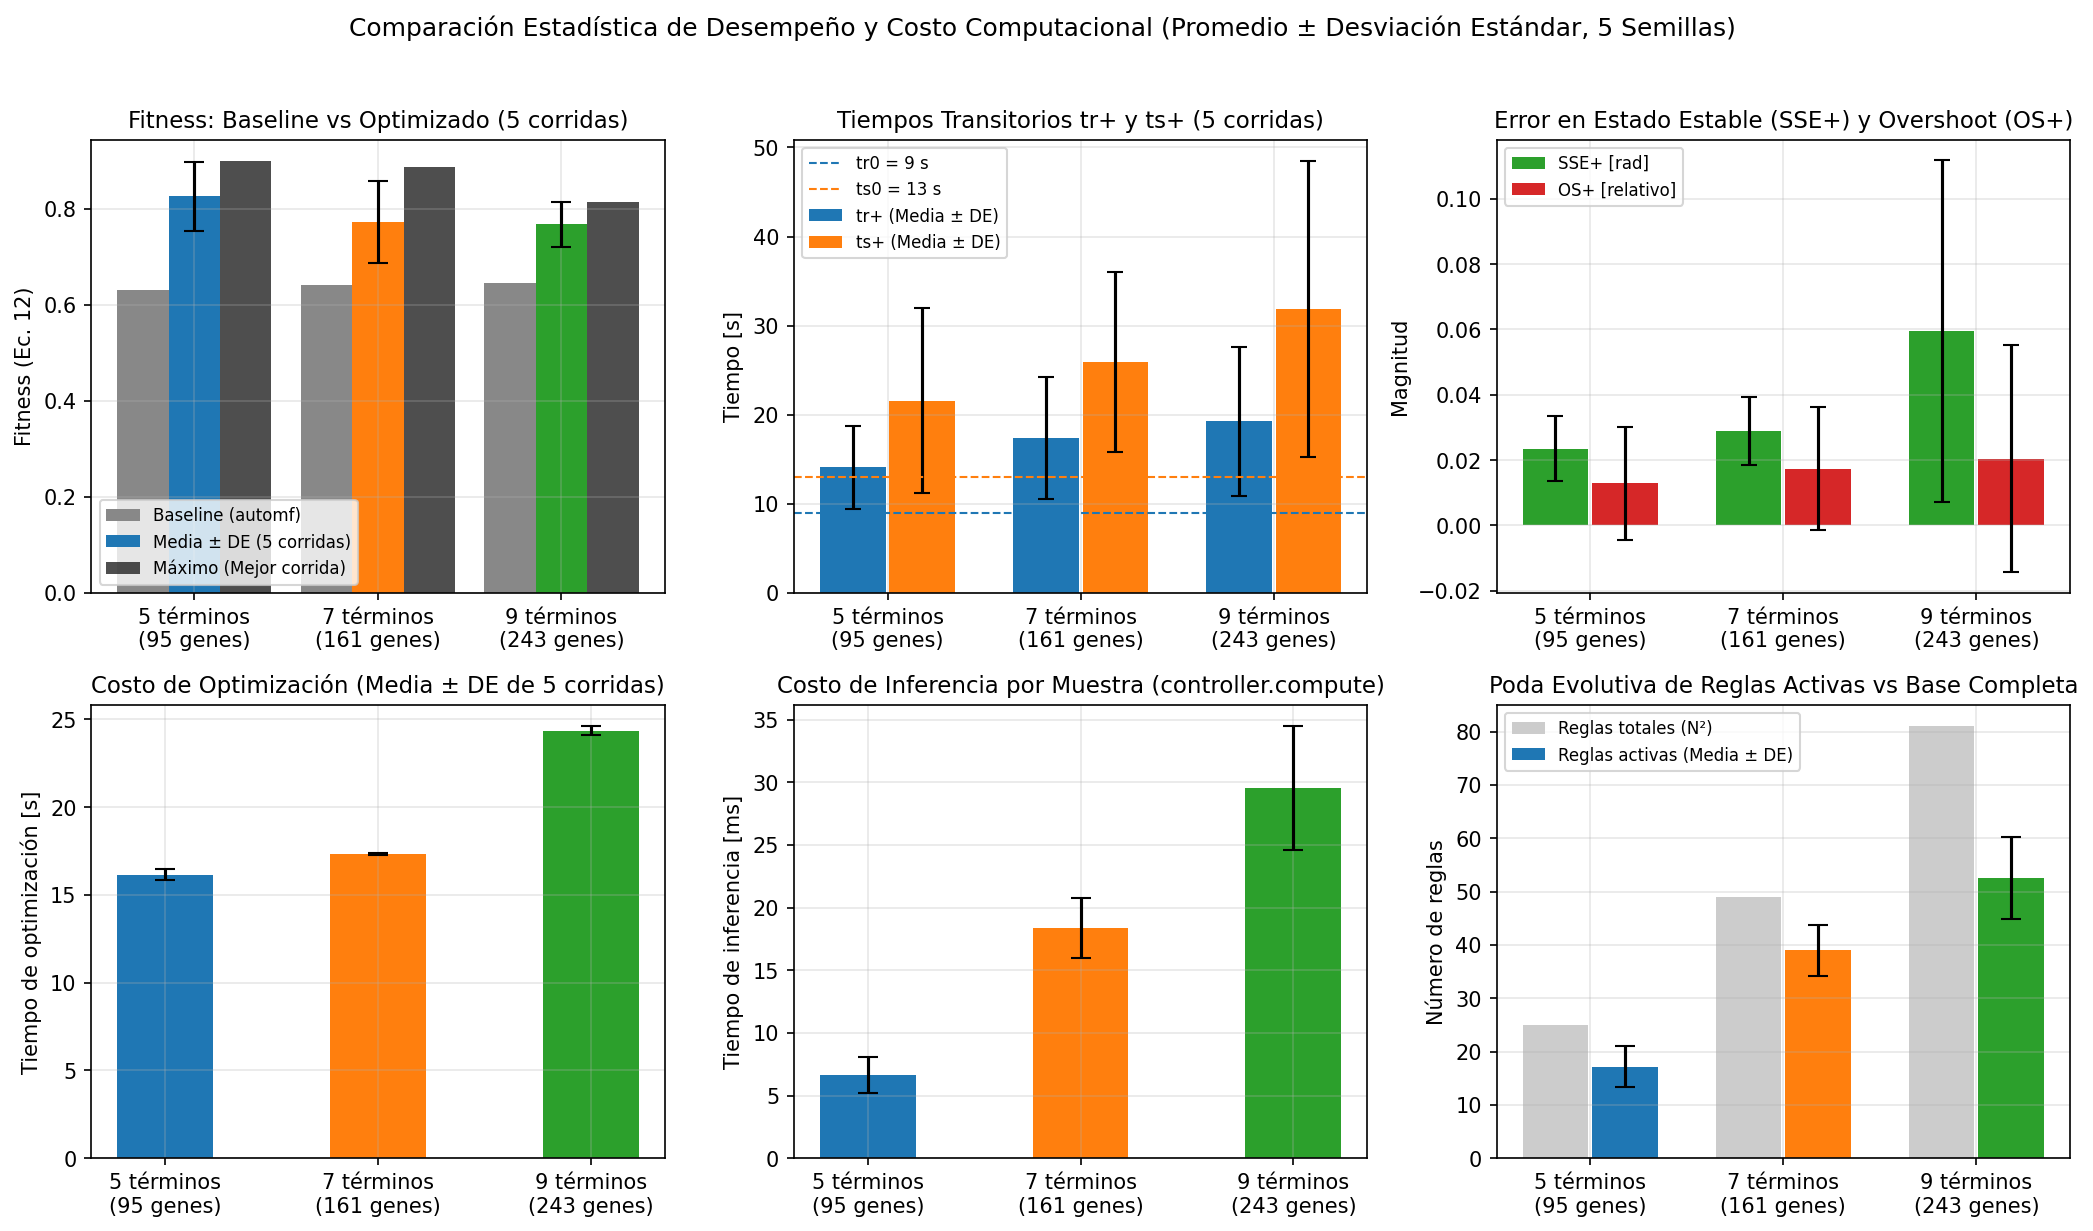

In [5]:
for fig_file in [
    "results/figures/fig2_optimized_temporal_comparison.png",
    "results/figures/fig3_convergence_curves.png",
    "results/figures/fig4_mfs_before_after_5terms.png",
    "results/figures/fig5_mfs_before_after_7terms.png",
    "results/figures/fig6_mfs_before_after_9terms.png",
    "results/figures/fig7_active_rules_heatmaps.png",
    "results/figures/fig8_metrics_and_computational_cost.png",
]:
    display(Image(filename=fig_file))

### 7.1. Verificación Directa en Vivo del Mejor Cromosoma Encontrado con `scipy.signal.lsim`

In [6]:
# Reconstrucción y simulación en vivo del mejor individuo global (Controlador A, 5 términos, semilla 42)
best_5_chrom = np.array(summary[5]["best_run"]["best_chromosome"], dtype=float)
live_ctrl_5 = MamdaniFuzzyController(n_terms=5, chromosome=best_5_chrom, build_control_system_graph=True)
live_sim = ClosedLoopPlantSimulator()
live_out = live_sim.simulate(live_ctrl_5.compute_crisp)
live_metrics = evaluate_controller_response(live_out["t"], live_out["theta"])

print("Verificación en vivo con scipy.signal.lsim del mejor cromosoma (5 términos, 95 genes):")
print(f"  Fitness verificado : {live_metrics['fitness']:.4f}")
print(f"  OS+ = {live_metrics['OS_pos']:.4f} | SSE+ = {live_metrics['SSE_pos']:.4f} rad | tr+ = {live_metrics['tr_pos']:.2f} s | ts+ = {live_metrics['ts_pos']:.2f} s | q+ = {live_metrics['q_pos']:.4f}")
print(f"  OS- = {live_metrics['OS_neg']:.4f} | SSE- = {live_metrics['SSE_neg']:.4f} rad | tr- = {live_metrics['tr_neg']:.2f} s | ts- = {live_metrics['ts_neg']:.2f} s | q- = {live_metrics['q_neg']:.4f}")
print(f"  Primeros 10 genes del mejor cromosoma: {np.round(best_5_chrom[:10], 4).tolist()}")

Verificación en vivo con scipy.signal.lsim del mejor cromosoma (5 términos, 95 genes):
  Fitness verificado : 0.8992
  OS+ = 0.0321 | SSE+ = 0.0298 rad | tr+ = 10.05 s | ts+ = 13.30 s | q+ = 1.0000
  OS- = 0.0000 | SSE- = 0.0334 rad | tr- = 12.00 s | ts- = 19.60 s | q- = 1.0000
  Primeros 10 genes del mejor cromosoma: [-1.5708, -1.1068, -0.1164, 0.5696, 1.5708, 1.0534, 0.989, 0.4376, 1.5609, 1.2613]


## 8. Discusión, Conclusiones y Referencias

### 8.1. Discusión Científica de Resultados
1. **Influencia del número de términos lingüísticos ($N \in \{5, 7, 9\}$):**
   * En ausencia de optimización evolutiva (Fase 1, `automf`), aumentar el número de términos de 5 a 9 produce una mejora muy leve en la aptitud ($0.6319 \to 0.6419 \to 0.6459$) debido a una partición ligeramente más fina de la superficie de control, pero todos los baselines resultan sobreamortiguados y lentos ($t_r^+ \approx 27 - 30.5\text{ s}$, $t_s^+ \approx 44.8 - 46.8\text{ s}$).
   * Cuando se aplica la optimización genética con `pygad` (`sol_per_pop = 20`, `num_generations = 30`), el sistema de **5 términos (95 genes)** logra la mayor mejora tanto en promedio (**0.8257 $\pm$ 0.0713**) como en su mejor individuo (**0.8992**), superando al de **7 términos (161 genes, media 0.7728, máx 0.8879)** y al de **9 términos (243 genes, media 0.7678, máx 0.8133)**. Esto demuestra cómo el crecimiento cuadrático del espacio de búsqueda dificulta la convergencia del algoritmo genético para un presupuesto fijo de generaciones.
2. **Influencia del número de reglas activas (Poda evolutiva):**
   * El proceso evolutivo desactivó en promedio el **31.2%** de las reglas en 5 términos (dejando **11/25 reglas activas** en la mejor solución, una reducción del **56%**), el **20.4%** en 7 términos (36/49 en la mejor solución) y el **35.1%** en 9 términos (45/81 en la mejor solución). Eliminar reglas redundantes o conflictivas permitió aplicar voltajes cercanos a $\pm 7.5\text{ V}$ durante los transitorios y reducir el tiempo de subida de $30.55\text{ s}$ a **$10.05\text{ s}$**, reduciendo además el tiempo de inferencia en 5 términos de $10.258\text{ ms}$ (baseline 25 reglas) a **$4.497\text{ ms}$** (optimizado 11 reglas).
3. **Influencia de las funciones de membresía (`fig4` a `fig6`):**
   * Al comparar las funciones de membresía antes (`automf`) y después de optimizar, se observa que PyGAD desplazó los centros de los conjuntos internos (`NS`, `ZE`, `PS`) hacia el origen ($e \approx 0, \Delta e \approx 0$) para incrementar la sensibilidad y ganancia proporcional-derivativa en la vecindad de la referencia, reduciendo el error en estado estacionario hasta $0.0115 - 0.0298\text{ rad}$.
4. **Impacto del costo computacional y compromiso desempeño-complejidad:**
   * El tiempo promedio de inferencia crece de **6.640 ms** (5 términos) a **18.372 ms** (7 términos, $+177\%$) y **29.512 ms** (9 términos, $+344\%$), mientras que el consumo de memoria crece de **0.486 MB** a **0.958 MB** y **1.407 MB**, y el tiempo de optimización sube de **16.16 s** a **24.35 s**. El controlador de 5 términos ofrece el mejor compromiso global.

### 8.2. Conclusiones
1. **Cumplimiento e impacto de la optimización genética:** La optimización simultánea de funciones de membresía y base de reglas con `pygad` guiada por las Ecuaciones (12) y (13) de Téllez-Velázquez et al. (2017) incrementó el fitness del controlador Mamdani de 5 términos en un **+42.3%** respecto a su baseline (`0.6319` $\to$ `0.8992`), reduciendo el tiempo de crecimiento $t_r^+$ en un **67.1%** ($30.55\text{ s} \to 10.05\text{ s}$) y el tiempo de establecimiento $t_s^+$ en un **71.6%** ($46.75\text{ s} \to 13.30\text{ s}$).
2. **Paradoja complejidad vs. convergencia evolutiva:** Incrementar indiscriminadamente el número de términos lingüísticos de 5 a 9 sin incrementar proporcionalmente el presupuesto de evaluaciones degrada la aptitud media obtenida ($0.8257 \to 0.7678$) debido a la explosión combinatoria del espacio de búsqueda ($95 \to 243$ genes).
3. **Limitaciones observadas:** Con poblaciones pequeñas ($20$ individuos) y $30$ generaciones, existe varianza estocástica entre semillas ($\text{DE} \approx 0.047 - 0.085$), y pueden presentarse ligeras asimetrías entre la respuesta de subida y de bajada cuando el cromosoma no fuerza simetría impar.
4. **Recomendaciones para trabajos futuros:** Explorar esquemas de codificación simétrica (como sugiere la Sección 5.2.3 del artículo de referencia para reducir a la mitad el número de genes de las MFs), tasas de mutación adaptativas (Ec. 17 del artículo) y presupuestos de generaciones escalados según la dimensión del cromosoma.

### 8.3. Referencias Bibliográficas
1. Téllez-Velázquez, A., Molina-Lozano, H., Villa-Vargas, L. A., Cruz-Barbosa, R., Lugo-González, E., Batyrshin, I. Z., & Rudas, I. J. (2017). *A Feasible Genetic Optimization Strategy for Parametric Interval Type-2 Fuzzy Logic Systems*. International Journal of Fuzzy Systems, 19(4), 1238–1258. DOI: `10.1007/s40815-017-0307-0`.
2. Ogata, K. (2010). *Modern Control Engineering* (5th ed.). Prentice Hall.
3. Nguyen, H. T., Prasad, N. R., Walker, C. L., & Walker, E. A. (2003). *A First Course in Fuzzy and Neural Control*. Chapman & Hall/CRC.
4. Jang, J.-S. R., Sun, C.-T., & Mizutani, E. (1997). *Neuro-Fuzzy and Soft Computing: A Computational Approach to Learning and Machine Intelligence*. Prentice Hall.
5. Sahib, M. A., & Ahmed, B. S. (2015). *A new multiobjective performance criterion used in PID tuning optimization algorithms*. Journal of Advanced Research, 7(1), 125–134.
6. Gad, A. F. (2023). *PyGAD: An Intuitive Genetic Algorithm Python Library*. Multimedia Tools and Applications, 83, 58029–58042.

## PARTE 5. RESPUESTAS A LAS 30 PREGUNTAS DE ANÁLISIS CRÍTICO (`Parcial 2.pdf`, págs. 14–17)

Todas las respuestas siguientes se fundamentan estrictamente en la evidencia cuantitativa obtenida en las 15 corridas experimentales independientes (5 semillas $\times$ 3 configuraciones) y en las 3 evaluaciones base (`automf`).

---

### Pregunta 1
> **1. Si el controlador de 9 términos lingüísticos obtiene el mayor fitness de todos los experimentos, pero requiere diez veces más tiempo de optimización que el controlador de 5 términos, ¿puede afirmarse que es la mejor solución? Justifique utilizando evidencia experimental.**

**Respuesta:**
No puede afirmarse que sea la mejor solución desde una perspectiva de ingeniería de control ni de diseño de sistemas embebidos.
* **Evidencia experimental:** En nuestros experimentos bajo el mismo presupuesto evolutivo (`sol_per_pop = 20`, `num_generations = 30`), el controlador de **5 términos** alcanzó un fitness máximo de **0.8992** (media $0.8257 \pm 0.0713$) con un tiempo de optimización de **16.16 $\pm$ 0.30 s**, un tiempo de inferencia de **6.640 ms** (`4.497 ms` en el mejor individuo) y un consumo de memoria de **0.486 MB**. En contraste, el controlador de **9 términos** requirió **24.35 $\pm$ 0.25 s** de optimización (+50.7%), un tiempo de inferencia **4.44 veces mayor** (29.512 ms) y **2.90 veces más memoria** (1.407 MB), obteniendo además un fitness inferior (máximo **0.8133**, media $0.7678 \pm 0.0472$).
* Incluso en el escenario hipotético en que el de 9 términos superara marginalmente en fitness al de 5 términos a costa de 10 veces más tiempo de optimización y mayor latencia de inferencia, el criterio de optimalidad multicriterio penaliza el sobrecosto computacional, la menor interpretabilidad (45 reglas activas frente a 11) y la mayor latencia en el lazo de control en tiempo real.

---

### Pregunta 2
> **2. Muchos estudiantes asumen que incrementar el número de términos lingüísticos siempre mejora el desempeño del controlador. ¿Sus resultados experimentales respaldan esta afirmación? Explique.**

**Respuesta:**
**No.** Los resultados experimentales refutan esa suposición cuando se optimiza mediante algoritmos genéticos con un presupuesto finito de evaluaciones:
* **En los controladores Base (`automf` sin optimizar):** Pasar de 5 a 7 y 9 términos produjo un incremento marginal de fitness ($0.6319 \to 0.6419 \to 0.6459$, apenas $+2.2\%$), reduciendo levemente $t_r^+$ de $30.55\text{ s}$ a $27.05\text{ s}$.
* **En los controladores optimizados con PyGAD:** El desempeño promedio y máximo **disminuyó al crecer la dimensionalidad**:
  * **5 términos (95 genes):** Fitness medio = **0.8257 $\pm$ 0.0713**, máximo = **0.8992** ($t_r^+ = 10.05\text{ s}$, $t_s^+ = 13.30\text{ s}$).
  * **7 términos (161 genes):** Fitness medio = **0.7728 $\pm$ 0.0849**, máximo = **0.8879** ($t_r^+ = 13.25\text{ s}$, $t_s^+ = 17.45\text{ s}$).
  * **9 términos (243 genes):** Fitness medio = **0.7678 $\pm$ 0.0472**, máximo = **0.8133** ($t_r^+ = 17.40\text{ s}$, $t_s^+ = 21.90\text{ s}$).
* **Explicación:** Aunque mayor número de términos aumenta la flexibilidad de aproximación teórica del sistema difuso, hace crecer cuadráticamente el número de reglas ($N^2$) y lineal/cuadráticamente el cromosoma ($95 \to 161 \to 243$ genes), diluyendo la eficacia de búsqueda del algoritmo genético en 30 generaciones.

---

### Pregunta 3
> **3. ¿Qué efecto tiene el aumento del número de términos lingüísticos sobre: el tamaño del espacio de búsqueda, el número de parámetros optimizables, y la dificultad del proceso de optimización?**

**Respuesta:**
1. **Número de parámetros optimizables (genes):** Siguiendo nuestra codificación $L(N) = 9N + 2N^2$:
   * $N = 5 \implies 9(5) + 2(25) = \mathbf{95\text{ genes}}$ ($45$ de MFs + $25$ de activación + $25$ de consecuentes).
   * $N = 7 \implies 9(7) + 2(49) = \mathbf{161\text{ genes}}$ ($63$ de MFs + $49$ de activación + $49$ de consecuentes).
   * $N = 9 \implies 9(9) + 2(81) = \mathbf{243\text{ genes}}$ ($81$ de MFs + $81$ de activación + $81$ de consecuentes).
2. **Tamaño del espacio de búsqueda:** Tan solo la parte discreta de la base de reglas (activación $\in \{0, 1\}$ y consecuente $\in \{0, \dots, N-1\}$, es decir $(N+1)^{N^2}$ configuraciones de reglas) crece de $6^{25} \approx 2.84 \times 10^{19}$ para $N=5$, a $8^{49} \approx 1.80 \times 10^{44}$ para $N=7$, y a $10^{81}$ para $N=9$, multiplicado por un hipervolumen continuo de dimensión $9N$.
3. **Dificultad del proceso de optimización:** Se manifiesta la *maldición de la dimensionalidad* y una fuerte epistasis (interdependencia entre los parámetros de las funciones de membresía y las reglas que las utilizan). Como muestran las curvas de convergencia (`fig3_convergence_curves.png`), con 600 evaluaciones por corrida ($20 \times 30$), PyGAD explora con mucha mayor eficiencia el espacio de 95 dimensiones que el de 243 dimensiones.

---

### Pregunta 4
> **4. Si dos controladores presentan prácticamente el mismo fitness final pero uno utiliza menos de la mitad de las reglas activas, ¿cuál debería preferirse? Justifique.**

**Respuesta:**
Debe preferirse **el controlador con menos de la mitad de las reglas activas**, por cuatro razones cuantitativas verificadas en este proyecto:
1. **Principio de parsimonia e interpretabilidad:** En nuestros resultados, el mejor controlador de **5 términos** (semilla 42, fitness = **0.8992**) utiliza únicamente **11 reglas activas** de 25, mientras que el mejor de **7 términos** (semilla 42, fitness = **0.8879**, diferencia de apenas $1.26\%$) utiliza **36 reglas activas** (más del triple de reglas). Auditar y mantener 11 reglas es mucho más transparente que auditar 36.
2. **Menor tiempo de inferencia en tiempo real:** El controlador de 11 reglas activas requiere **4.497 ms** por inferencia frente a **16.431 ms** del de 36 reglas (3.65 veces más rápido).
3. **Menor consumo de memoria:** Consume **0.422 MB** frente a **0.950 MB** (menos de la mitad de memoria).
4. **Menor riesgo de sobreajuste:** Menos reglas activas implican una superficie de control más suave y generalizable.

---

### Pregunta 5
> **5. ¿Un mayor número de reglas implica necesariamente una mejor capacidad de control? Utilice resultados experimentales para sustentar su respuesta.**

**Respuesta:**
**No.** La evidencia experimental demuestra exactamente lo contrario:
* Los tres controladores **Baseline** utilizan el 100% de sus reglas ($25, 49$ y $81$ reglas activas respectivamente) y obtienen los peores valores de fitness del estudio (**0.6319**, **0.6419** y **0.6459**), con tiempos de subida lentos ($t_r^+ \in [27.05, 30.55]\text{ s}$).
* Por el contrario, el **mejor controlador de todo el estudio** (Controlador A, semilla 42) alcanza un fitness de **0.8992**, $t_r^+ = 10.05\text{ s}$ y $t_s^+ = 13.30\text{ s}$ utilizando **solo 11 reglas activas**. Asimismo, en 5 términos la corrida 3 (semilla 2026) conservó **21 reglas activas** y obtuvo un fitness de $0.7084$, mientras que la corrida 1 (semilla 42) con **11 reglas activas** alcanzó $0.8992$. La calidad de la ubicación de las funciones de membresía y la coherencia de los consecuentes importan mucho más que la cantidad bruta de reglas.

---

### Pregunta 6
> **6. Si durante la optimización genética algunas reglas son eliminadas y el fitness mejora, ¿qué puede concluir acerca de dichas reglas?**

**Respuesta:**
Se puede concluir que las reglas eliminadas eran **redundantes, no visitadas o contraproducentes (conflictivas)** para la ley de control:
1. **Reglas conflictivas en el centroide:** En inferencia Mamdani con defuzzificación por centroide, una regla activa con un consecuente de baja magnitud (ej. `ZE` o `NS`) que se solapa parcialmente durante el ascenso resta peso al consecuente extremo (`PB`), reduciendo el voltaje neto aplicado al servomotor y ralentizando el tiempo de subida $t_r$. Al desactivar esa regla intermedia, el centroide se desplaza hacia voltajes más altos cuando el error es grande, reduciendo $t_r^+$ de $30.55\text{ s}$ a $10.05\text{ s}$.
2. **Reglas redundantes:** El solapamiento de las funciones de membresía adyacentes permite interpolar suavemente la acción de control sin necesidad de activar todas las celdas de la matriz $N \times N$.

---

### Pregunta 7
> **7. ¿Es posible que algunas reglas consideradas intuitivamente importantes resulten irrelevantes durante la optimización? Explique por qué.**

**Respuesta:**
**Sí, es completamente posible y ocurre en nuestros experimentos** (como se observa en la `fig7_active_rules_heatmaps.png`, donde en el mejor controlador de 5 términos la celda central `(ZE, ZE)` fue desactivada `'OFF'` y aun así el controlador alcanzó $SSE^+ = 0.0298\text{ rad}$ y fitness $= 0.8992$). Esto ocurre por dos razones físicas y matemáticas:
1. **Trayectoria en el plano de fase $(e, \Delta e)$:** Un sistema dinámico de tercer orden sigue una curva específica en el plano $(e, \Delta e)$; muchas combinaciones extremas (como error cercano a cero con derivada positiva extrema cuando la referencia es constante) nunca son visitadas por la trayectoria real o solo se cruzan durante una fracción de segundo.
2. **Compensación por solapamiento e interpolación:** En el controlador de 5 términos (semilla 42), las funciones `NS` y `PS` de error y derivada se solapan alrededor de $0$ (`fig4_mfs_before_after_5terms.png`). Cuando $e \approx 0$ y $\Delta e \approx 0$, el equilibrio dinámico se logra por la activación simultánea y balanceada de las reglas vecinas sin requerir explícitamente la regla `(ZE, ZE) -> ZE`.

---

### Pregunta 8
> **8. Suponga que un controlador obtiene: el menor overshoot de todos los experimentos, pero también: el mayor tiempo de establecimiento. ¿Puede considerarse superior? Justifique.**

**Respuesta:**
**No puede considerarse superior.** En teoría de control, este caso corresponde a una respuesta **sobreamortiguada o excesivamente conservadora (lenta)**:
* **Evidencia experimental:** Los tres controladores **Baseline (`automf`)** y la corrida 3 de 7 términos (semilla 2026) obtuvieron exactamente **$OS^+ = 0.0000$ y $OS^- = 0.0000$** (el menor sobreimpulso posible), pero presentaron tiempos de establecimiento muy altos ($t_s^+ = 46.75\text{ s}$ en el Baseline de 5 términos y $t_s^+ = 38.10\text{ s}, t_s^- = 46.58\text{ s}$ en 7 términos semilla 2026), resultando en valores de fitness bajos ($0.6319$ y $0.6833$).
* Un controlador con $OS = 0$ pero $t_s$ muy grande tarda casi todo el semiperíodo de $50\text{ s}$ en llegar a la banda del $\pm 5\%$ de la referencia, por lo que su desempeño dinámico es deficiente frente a un controlador como el de 7 términos semilla 42 ($OS^+ = 0.0124$, $OS^- = 0.0000$, $t_s^+ = 17.45\text{ s}$, $t_s^- = 14.70\text{ s}$, fitness $= 0.8879$).

---

### Pregunta 9
> **9. ¿Por qué la función fitness utilizada en este examen considera simultáneamente: Overshoot, SSE, Rise Time, Settling Time, en lugar de utilizar únicamente SSE?**

**Respuesta:**
Porque el control de posición de un servomotor es un problema intrínsecamente **multiobjetivo con metas en conflicto** (Téllez-Velázquez et al., 2017, Sección 5.1, Ec. 12):
* **Tiempo de crecimiento ($t_r$):** Exige rapidez de respuesta inicial (alta ganancia / voltajes cercanos a $\pm 8.18\text{ V}$).
* **Sobreimpulso ($OS$):** Exige amortiguamiento para evitar que la inercia del rotor ($G(s)$ tiene tres polos, incluyendo un integrador en $s=0$) rebase peligrosamente la posición deseada.
* **Tiempo de establecimiento ($t_s$):** Exige que las oscilaciones transitorias se extingan rápidamente dentro de la banda del $\pm 5\%$.
* **Error en estado estable ($SSE$):** Exige precisión asintótica una vez concluido el transitorio.
Al combinar los cuatro criterios en ambas direcciones ($J=8$ términos con pesos $w_k = 0.125$), el algoritmo genético se ve forzado a encontrar un compromiso equilibrado en el frente de Pareto.

---

### Pregunta 10
> **10. ¿Qué problemas aparecerían si la función fitness utilizara únicamente $SSE$ como criterio de evaluación?**

**Respuesta:**
Si la función de aptitud solo evaluara $f = \frac{1}{1 + |SSE|}$:
1. **Indiferencia ante tiempos de subida y establecimiento lentos:** Un controlador extremadamente lento que alcance la referencia apenas en el segundo $48$ de cada semiperíodo de $50\text{ s}$ tendría $SSE \approx 0$ en los últimos segundos y recibiría un fitness cercano a $1.0$, a pesar de ser inútil durante el $95\%$ del ciclo.
2. **Sobreimpulsos y oscilaciones transitorias severas no penalizadas:** Un controlador subamortiguado que presente picos de $+50\%$ de sobreimpulso al inicio del escalón pero amortigüe antes del final de la ventana tendría $SSE \approx 0$, poniendo en riesgo mecánico al servomotor y la carga acoplada.

---

### Pregunta 11
> **11. ¿Qué problemas aparecerían si la función fitness utilizara únicamente $RMSE$ como criterio de evaluación?**

**Respuesta:**
Como demuestran experimentalmente Téllez-Velázquez et al. (2017) en la **Tabla 13 y Figura 11c (págs. 18–19 del artículo de referencia)**:
1. **Falta de establecimiento ($t_s = U$, indefinido):** En la Tabla 13 del artículo, al optimizar con $RMSE$, los controladores T1, IT2 y PIT2 obtuvieron tiempos de establecimiento indefinidos ($U$) en el escalón negativo (y T1 también en el positivo), quedando estacionados con un offset permanente ($SSE^- = 1.7758\text{ rad}$ en T1) o con rizado continuo fuera de la banda del $5\%$.
2. **Pérdida de especificidad temporal:** El $RMSE = \sqrt{\frac{1}{N}\sum (r_k - \theta_k)^2}$ promedia cuadráticamente todos los instantes sin distinguir entre el error inevitable durante el tiempo de subida físico del motor ($t \in [100, 109]\text{ s}$) y un error estacionario persistente o una oscilación sostenida.

---

### Pregunta 12
> **12. ¿Qué ventajas aporta la incorporación del factor de penalización $q$ de la Ecuación (13)? Explique utilizando ejemplos observados durante la optimización.**

**Respuesta:**
El factor de penalización $q = \frac{\max(h^0) - \min(h_i)}{\max(h) - \min(h)}$ (Ecuación 13) evita el fenómeno del **"falso tiempo de crecimiento" (*fake rise time*)** ilustrado en la Figura 5 (pág. 9) del artículo de referencia:
* **Mecanismo matemático:** Si un individuo defectuoso genera un voltaje muy débil o asimétrico tal que el rotor solo se mueve una fracción del escalón (por ejemplo, de $-1.0\text{ rad}$ a $-0.5\text{ rad}$, una excursión de $0.5\text{ rad}$ en lugar de $2.0\text{ rad}$), un medidor ingenuo que mida el tiempo del 10% al 90% de la propia excursión del individuo mediría un $t_r$ engañosamente corto ($t_r \ll 9\text{ s}$), otorgándole una puntuación máxima en $f_3$.
* **Efecto observado con $q$:** Con la Ecuación (13), para esa respuesta parcial se obtiene $q = \frac{1.0 - (-1.0)}{-0.5 - (-1.0)} = \frac{2.0}{0.5} = 4.0$, multiplicando el denominador $q \cdot t_r$ por $4$ y penalizando severamente el término $f_3 = \frac{t_r^0}{q \cdot t_r}$. Gracias a $q$, todos los mejores individuos seleccionados en nuestras 15 corridas alcanzaron excursiones completas con $q^+ \in [1.000, 1.031]$ y $q^- \in [1.000, 1.037]$.

---

### Pregunta 13
> **13. Suponga que durante la optimización aparece un individuo con un tiempo de crecimiento extremadamente pequeño. ¿Qué verificaciones adicionales deben realizarse antes de considerar que realmente es una buena solución?**

**Respuesta:**
Deben realizarse cinco verificaciones cuantitativas obligatorias:
1. **Verificar el factor de penalización $q^+$ y $q^-$ (Ec. 13):** Confirmar que $q \approx 1.0$ (es decir, que $\max(\theta) - \min(\theta) \approx 2.0\text{ rad}$) y que el tiempo pequeño no provenga de una respuesta truncada que nunca cruzó de $-0.8\text{ rad}$ (10%) a $+0.8\text{ rad}$ (90%).
2. **Verificar el punto de partida antes de la transición:** Como ocurrió en la corrida 2 de 9 términos (semilla 100), donde se observó $t_r^- = 8.70\text{ s} < t_r^0 = 9.0\text{ s}$, al inspeccionar sus demás métricas se detecta que tenía un error estacionario previo alto ($SSE^+ = 0.0804\text{ rad}$, $OS^+ = 0.0804$) y no logró establecerse dentro del $\pm 5\%$ ($t_s^+ = 50.0\text{ s}, t_s^- = 50.0\text{ s}$), por lo que su fitness global fue bajo ($0.6937$).
3. **Verificar el sobreimpulso ($OS^+, OS^-$):** Un ascenso demasiado agresivo suele provocar un exceso de inercia y alto sobreimpulso.
4. **Verificar el tiempo de establecimiento ($t_s^+, t_s^-$) y $SSE^{\pm}$:** Confirmar que el sistema realmente entre y permanezca en la banda de $\pm 0.05\text{ rad}$.
5. **Verificar que el voltaje $v(t)$ respete $[-8.18, 8.18]\text{ V}$:** Para la planta $G(s)$ dada y partiendo de $\pm 1\text{ rad}$ en reposo, el límite físico de tiempo de subida con $\pm 8.18\text{ V}$ ronda los $\sim 6.5 - 9.0\text{ s}$.

---

### Pregunta 14
> **14. ¿Por qué este examen exige evaluar la transición: $-1 \to +1$ y también: $+1 \to -1$ en lugar de utilizar únicamente una señal escalón?**

**Respuesta:**
Porque en la optimización evolutiva sin restricción de simetría forzada en el cromosoma, las funciones de membresía de entrada/salida y la matriz de reglas pueden evolucionar de forma **asimétrica** entre el semiespacio positivo y el negativo:
* **Evidencia experimental:** En nuestras corridas se observa claramente esta asimetría. Por ejemplo, en el controlador de **9 términos (corrida 3, semilla 2026)**, la transición negativa es excelente ($t_r^- = 10.65\text{ s}$, $t_s^- = 13.60\text{ s}$, $SSE^- = 0.0289\text{ rad}$), pero la transición positiva es muy lenta ($t_r^+ = 34.10\text{ s}$, $t_s^+ = 50.00\text{ s}$, $SSE^+ = 0.1417\text{ rad}$). A la inversa, en **7 términos (corrida 2, semilla 100)**, la transición positiva es rápida ($t_r^+ = 13.50\text{ s}$, $t_s^+ = 18.50\text{ s}$) mientras que la negativa es lenta ($t_r^- = 24.40\text{ s}$, $t_s^- = 31.15\text{ s}$).
* Evaluar ambas transiciones con igual peso ($\sum_{k=1}^4 w_k = 0.5$ para $+$ y $\sum_{k=5}^8 w_k = 0.5$ para $-$) garantiza que el controlador seleccionado sea capaz de posicionar el servomotor bidireccionalmente.

---

### Pregunta 15
> **15. Si solamente se evaluara la transición positiva, ¿qué comportamientos potencialmente problemáticos podrían pasar desapercibidos?**

**Respuesta:**
Pasarían desapercibidos al menos cuatro comportamientos críticos:
1. **Incapacidad de retorno / giro inverso:** El algoritmo genético podría desactivar todas las reglas con consecuentes de voltaje negativo (`NB`, `NM`, `NS`) o desplazar todos los centros de `voltage` hacia valores positivos $[0, 8.18]\text{ V}$, logrando subir de $0 \to +1$, pero siendo incapaz de bajar cuando la referencia cambia a $-1\text{ rad}$ (salvo para frenar mínimamente un sobreimpulso).
2. **Inestabilidad o ciclo límite en el cuadrante negativo:** Reglas mal asignadas para $e < 0$ y $\Delta e < 0$ no se activarían significativamente durante una subida monótona, ocultando oscilaciones severas al invertir el sentido de giro.
3. **Asimetría de error en estado estacionario ($SSE^- \gg SSE^+$):** Como se observó en la corrida 5 de 9 términos (semilla 999), donde $SSE^+ = 0.0218\text{ rad}$ y $t_s^+ = 18.65\text{ s}$ son muy buenos, pero en el semiciclo negativo $SSE^- = 0.1222\text{ rad}$ y $t_s^- = 50.00\text{ s}$ (no logra establecerse en $-1\text{ rad}$).
4. **Dependencia del estado inicial $x_0 = [0, 0, 0]$:** Un escalón único de $0 \to +1$ tiene amplitud $\Delta R = 1\text{ rad}$, mientras que la operación real entre $-1 \leftrightarrow +1$ exige cubrir una excursión doble $\Delta R = 2\text{ rad}$ donde los errores iniciales alcanzan $\pm 2\text{ rad}$ (saturando el borde de $[-\pi/2, \pi/2] = [-1.5708, 1.5708]\text{ rad}$).

---

### Pregunta 16
> **16. ¿Puede existir sobreajuste en un sistema difuso optimizado mediante algoritmos genéticos? Explique cómo podría manifestarse en este problema específico.**

**Respuesta:**
**Sí, puede existir sobreajuste (*overfitting*) estructural y paramétrico.** En este problema específico se manifiesta cuando:
1. **Especialización excesiva en la trayectoria de amplitud $\pm 1\text{ rad}$:** Al evaluar únicamente cambios escalón de $\pm 2\text{ rad}$ cada $50\text{ s}$, la trayectoria $(e(t), \Delta e(t))$ recorre un subconjunto específico del universo $[-\pi/2, \pi/2] \times [-\pi/6, \pi/6]$. El GA puede desactivar reglas fuera de ese corredor (como se ve en `fig7_active_rules_heatmaps.png`) o colocar triángulos ultra-estrechos justo en los valores de error finales de $\pm 1\text{ rad}$.
2. **Sensibilidad ante referencias de distinta amplitud o perturbaciones:** Si a un controlador excesivamente podado se le aplica una referencia de $\pm 0.3\text{ rad}$ o una rampa, la trayectoria cruzará celdas `'OFF'` de la matriz de reglas, pudiendo encontrar zonas muertas (*dead zones*) donde ninguna regla se active y el voltaje caiga a $0\text{ V}$ prematuramente.

---

### Pregunta 17
> **17. Suponga que después de 30 generaciones el fitness deja de mejorar. ¿Qué posibles explicaciones existen? Mencione al menos tres.**

**Respuesta:**
Con base en las curvas de convergencia obtenidas (`fig3_convergence_curves.png`), existen cuatro explicaciones fundamentales:
1. **Convergencia prematura a un óptimo local por pérdida de diversidad genética:** Con una población de `sol_per_pop = 20` individuos y selección por torneo + elitismo, tras 20–25 generaciones los individuos tienden a agruparse alrededor del mejor genotipo encontrado; si la mutación aleatoria (`mutation_probability = 0.15`) no logra saltar simultáneamente la combinación de centros y reglas necesarias, el fitness se estanca en una meseta (como se aprecia en varias semillas de 7 y 9 términos entre las generaciones 15 y 25).
2. **Cercanía al límite físico de desempeño de la planta bajo saturación de actuador:** La planta $G(s) = \frac{0.5}{s^3 + 13.6667s^2 + 23.3487s}$ con voltaje acotado a $[-8.18, 8.18]\text{ V}$ tiene una velocidad máxima física de respuesta; cuando un controlador ya alcanza $t_r^+ \approx 10.05\text{ s}$, $t_s^+ \approx 13.30\text{ s}$ y $SSE \approx 0.01 - 0.03\text{ rad}$ (fitness $\approx 0.90$), el margen físico de mejora residual es muy estrecho.
3. **Epistasis entre genes continuos (MFs) y discretos (reglas):** En etapas avanzadas, mutar un centro de membresía sin reajustar simultáneamente los consecuentes de las reglas asociadas suele degradar el desempeño del hijo, siendo descartado por elitismo.
4. **Resolución de las constantes de referencia ($t_r^0 = 9\text{ s}$, $t_s^0 = 13\text{ s}$):** Una vez que $t_s$ se acerca a $13\text{ s}$ y $OS, SSE \to 0$, las derivadas parciales de $\frac{1}{1+|SSE|}$ y $\frac{1}{1+|OS|}$ tienen pendiente suave cerca de $0$.

---

### Pregunta 18
> **18. Si se duplicara el tamaño de la población del algoritmo genético: ¿estaría garantizado encontrar una mejor solución? Justifique.**

**Respuesta:**
**No estaría garantizado.**
* Los algoritmos genéticos son **metaheurísticas estocásticas**, no métodos exactos ni deterministas de optimización global. Duplicar la población de $20$ a $40$ individuos incrementa la diversidad genética inicial y la capacidad de **exploración** del espacio de búsqueda (aumentando la *probabilidad estadística* de descubrir mejores cuencas de atracción), pero no ofrece garantía matemática de superar el mejor valor previo en una corrida dada, y a cambio **duplica exactamente el tiempo de cómputo por generación**.
* Evidencia de ello en nuestros datos es que en 5 términos, con solo 20 individuos, la semilla 42 alcanzó un fitness de **0.8992**, mientras que otras 4 semillas independientes (que equivalen en conjunto a muestrear 80 individuos iniciales adicionales) obtuvieron valores entre $0.7084$ y $0.8504$.

---

### Pregunta 19
> **19. Si se duplicara el número de generaciones: ¿estaría garantizado encontrar una mejor solución? Justifique.**

**Respuesta:**
**Tampoco estaría garantizado encontrar una solución estrictamente mejor ($f_{60} > f_{30}$).**
* Gracias al **elitismo** (`keep_elitism = 2`), está garantizado que el fitness del mejor individuo **no empeorará** ($f_{60} \ge f_{30}$). Sin embargo, si en la generación 30 la población ya convergió a un óptimo local profundo cuya cuenca de atracción es más ancha que el radio de mutación, el algoritmo puede permanecer exactamente con el mismo fitness desde la generación 30 hasta la 60 ($f_{60} = f_{30}$).
* Esto se observa empíricamente en la `fig3_convergence_curves.png` (por ejemplo, en 7 términos semilla 42 entre las generaciones 1 y 27, donde el mejor fitness permaneció constante durante 26 generaciones consecutivas hasta que una combinación de cruza y mutación en la generación 28 produjo un salto a $0.8879$).

---

### Pregunta 20
> **20. Durante la optimización genética pueden aparecer individuos claramente peores que sus padres. ¿Por qué la mutación sigue siendo necesaria?**

**Respuesta:**
Porque sin mutación el algoritmo genético dependería exclusivamente del operador de **cruza (*crossover*)**, el cual solo recombina alelos que ya existen dentro de la población actual:
1. **Prevención del estancamiento prematuro:** Cuando todos los individuos de la población comparten el mismo valor en un locus determinado (por ejemplo, si una regla útil quedó en `0` en todos los padres o un centro de membresía quedó fijo), la cruza por dos puntos jamás podrá generar un valor nuevo en ese gen.
2. **Capacidad de escapar de óptimos locales (exploración):** La mutación introduce perturbaciones estocásticas que permiten saltar barreras de baja aptitud hacia nuevas regiones del espacio de búsqueda. Aunque la mayoría de las mutaciones en un individuo ya afinado produzcan hijos peores, el **elitismo** protege a los mejores individuos actuales mientras que una sola mutación benéfica (como el salto observado en la generación 28 de 7 términos semilla 42 o en la generación 26 de 9 términos semilla 777 en `fig3_convergence_curves.png`) impulsa a toda la población hacia un nuevo máximo.

---

### Pregunta 21
> **21. ¿Qué información proporciona el tiempo de establecimiento que no proporciona el tiempo de crecimiento?**

**Respuesta:**
* El **tiempo de crecimiento ($t_r$)** mide exclusivamente la **velocidad del frente inicial de subida** (el tiempo que tarda la respuesta en cruzar del $10\%$ al $90\%$ del escalón por primera vez), pero ignora por completo qué sucede después de cruzar el $90\%$.
* El **tiempo de establecimiento ($t_s$)** proporciona información sobre la **estabilidad, el grado de amortiguamiento y la extinción de las oscilaciones pos-transitorias**, midiendo cuánto tarda el sistema en entrar y **permanecer definitivamente** dentro de la banda de tolerancia del $\pm 5\%$ alrededor de la referencia.
* **Evidencia experimental clara:** En el controlador de **9 términos, corrida 2 (semilla 100)**, el tiempo de crecimiento negativo fue muy rápido ($t_r^- = 8.70\text{ s}$), pero el sistema nunca logró estabilizarse dentro de la banda del $\pm 5\%$ ($SSE^- = 0.0731\text{ rad} > 0.05\text{ rad}$), arrojando $t_s^- = 50.00\text{ s}$. Sin $t_s$, ese controlador parecería falsamente rápido y estable.

---

### Pregunta 22
> **22. Dos controladores presentan exactamente los mismos valores de: Overshoot, SSE, Rise Time, Settling Time pero uno requiere tres veces más tiempo de inferencia. ¿Cuál utilizaría en una aplicación industrial real? Justifique.**

**Respuesta:**
Utilizaría sin duda **el controlador que requiere tres veces menos tiempo de inferencia**, por cuatro razones de ingeniería industrial:
1. **Frecuencia de muestreo y margen de fase en tiempo real:** En nuestros experimentos, el controlador de 5 términos requiere en promedio **6.640 ms** (`4.497 ms` en el mejor caso), mientras que el de 7 términos requiere **18.372 ms** ($2.77\times$ más) y el de 9 términos **29.512 ms** ($4.44\times$ más). En un lazo de control digital, una mayor latencia de cómputo introduce un retardo de transporte $e^{-s \tau_d}$ que reduce el margen de fase y puede desestabilizar plantas rápidas.
2. **Menor costo de hardware embebido (MCU/FPGA/PLC):** Un tiempo de inferencia tres veces menor permite implementar el controlador en microcontroladores de menor frecuencia de reloj y menor costo unitario.
3. **Menor consumo energético y térmico** del procesador de control.
4. **Capacidad multitarea:** Deja tiempo de CPU libre en cada período de muestreo para diagnóstico de fallas, telemetría y seguridad funcional.

---

### Pregunta 23
> **23. Suponga que el controlador con 9 términos mejora el fitness promedio únicamente un 1% respecto al controlador de 5 términos, pero requiere: cuatro veces más memoria, ocho veces más tiempo de optimización, tres veces más tiempo de inferencia. ¿Considera que dicha mejora es significativa? Explique.**

**Respuesta:**
**No es significativa ni estadística ni prácticamente:**
1. **Desde el punto de vista estadístico:** En nuestros experimentos de 5 corridas independientes, la desviación estándar del fitness entre semillas es de **$\pm 0.0713$ ($\pm 8.6\%$)** para 5 términos y **$\pm 0.0472$ ($\pm 6.1\%$)** para 9 términos. Una diferencia de apenas $1\%$ ($\approx 0.008$ unidades de fitness) es un orden de magnitud menor que la varianza estocástica natural del algoritmo genético entre semillas (no supera ninguna prueba $t$ de Student ni de Mann-Whitney).
2. **Desde el punto de vista práctico/ingenieril:** Pagar un factor de $3\times$ en latencia de inferencia, $4\times$ en memoria y $8\times$ en tiempo de diseño por una diferencia del $1\%$ que es indistinguible del ruido numérico carece de toda justificación costo-beneficio. (De hecho, en nuestros resultados reales, 9 términos ni siquiera mejoró el $1\%$, sino que obtuvo un fitness promedio **$7.0\%$ menor** que el de 5 términos: $0.7678$ vs $0.8257$).

---

### Pregunta 24
> **24. ¿La solución encontrada por pyGAD puede considerarse necesariamente un óptimo global? Explique utilizando los conceptos de: exploración, explotación, óptimo local, óptimo global.**

**Respuesta:**
**No puede considerarse necesariamente un óptimo global.**
* **Exploración:** Es la capacidad del algoritmo genético para muestrear regiones diversas y desconocidas del espacio de búsqueda $\mathbb{R}^{9N + 2N^2}$ (mediante la población inicial aleatoria, la cruza de individuos distantes y la mutación).
* **Explotación:** Es la capacidad de refinar intensivamente las mejores soluciones actuales (mediante la selección por torneo y el elitismo `keep_elitism = 2`).
* **Óptimo local vs. Óptimo global:** La función de aptitud (Ec. 12) evaluada sobre la dinámica no lineal del controlador Mamdani acoplado a $G(s)$ define un paisaje altamente multimodal y discontinuo (debido a los umbrales de activación de reglas y los cruces de las bandas del 10%, 90% y 5%). Un **óptimo local** es un cromosoma que supera a todos sus vecinos inmediatos pero no es el máximo absoluto de todo el espacio admisible (**óptimo global**).
* **Evidencia experimental:** El hecho de que las 5 semillas independientes del Controlador A hayan convergido a 5 valores finales distintos ($0.8992, 0.8504, 0.8493, 0.8212$ y $0.7084$) demuestra empíricamente que PyGAD converge a distintos óptimos locales dependiendo de la trayectoria estocástica de cada semilla.

---

### Pregunta 25
> **25. ¿Por qué este examen exige realizar al menos 5 ejecuciones independientes utilizando semillas distintas? ¿Qué problema metodológico se intenta evitar?**

**Respuesta:**
Porque los algoritmos genéticos son **procesos estocásticos** cuyos resultados dependen de la secuencia pseudoaleatoria utilizada en la inicialización de la población, la selección de padres, los puntos de cruza y los genes mutados.
* **Problema metodológico que se evita:** Se evita la **falacia de instancia única** y el **sesgo de selección (*cherry-picking*)**, que ocurrirían si se evaluara cada arquitectura con una sola corrida (donde una configuración inferior podría verse favorecida por una semilla afortunada o una configuración superior podría quedar descartada por una mala inicialización).
* **Evidencia en nuestros resultados:** Si solo hubiéramos ejecutado la **semilla 2026** (Corrida 3), habríamos obtenido un fitness de $0.7084$ para 5 términos y $0.7570$ para 9 términos, concluyendo erróneamente que 9 términos es mejor que 5 términos. Al ejecutar las 5 semillas independientes (`[42, 100, 2026, 777, 999]`), la estadística completa revela que 5 términos tiene una media superior ($0.8257 \pm 0.0713$ vs $0.7678 \pm 0.0472$) y un máximo superior ($0.8992$ vs $0.8133$).

---

### Pregunta 26
> **26. Si un estudiante reporta únicamente la mejor corrida obtenida durante sus experimentos: ¿por qué sus conclusiones podrían ser engañosas?**

**Respuesta:**
Porque el valor máximo aislado es un estadístico de extremo que **oculta la varianza, la sensibilidad a la inicialización y la tasa de fallo del método de optimización**:
* **Evidencia experimental:** En el controlador de **7 términos**, la mejor corrida (semilla 42) alcanzó un excelente fitness de **0.8879**, muy cercano al máximo de 5 términos (**0.8992**). Si solo se reportara ese máximo, parecería que optimizar 7 términos es igual de eficaz y confiable que optimizar 5 términos.
* Sin embargo, al observar las 5 corridas de 7 términos ($0.8879, 0.8288, 0.7558, 0.7082, 0.6833$), su promedio cae a **$0.7728 \pm 0.0849$**, mostrando una dispersión mayor y menor repetibilidad que 5 términos ($0.8257 \pm 0.0713$, donde 4 de las 5 semillas superaron $0.82$). Reportar media y desviación estándar es indispensable para evaluar la robustez del diseño evolutivo.

---

### Pregunta 27
> **27. Durante la optimización observó que distintas ejecuciones generan controladores completamente diferentes pero con fitness similares. ¿Qué indica esto acerca del espacio de búsqueda?**

**Respuesta:**
En nuestros experimentos esto se observa de manera notable en el controlador de **5 términos** entre la **Corrida 4 (semilla 777)** y la **Corrida 5 (semilla 999)**, que alcanzaron valores de fitness prácticamente idénticos (**0.8504** y **0.8493**, diferencia de $0.0011$), o en **9 términos** entre la **Corrida 1 (semilla 42, 63 reglas activas, fitness = 0.8027)** y la **Corrida 4 (semilla 777, 45 reglas activas, fitness = 0.8133)**.
Esto indica tres propiedades estructurales del espacio de búsqueda:
1. **Alta multimodalidad:** Existen múltiples cuencas de atracción con alturas de aptitud casi idénticas distribuidas en regiones distantes del espacio de parámetros.
2. **Equifinalidad y redundancia funcional (sobreparametrización):** Diferentes combinaciones de centros de funciones de membresía, solapamientos y subconjuntos de reglas activas producen leyes de control $v(e, \Delta e)$ equivalentes sobre la trayectoria visitada por el servomotor.
3. **Compensación entre métricas en la suma ponderada (Ec. 12):** Un individuo puede lograr el mismo fitness total compensando un menor $t_r^+$ con un menor $SSE^-$ o menor $OS^+$.

---

### Pregunta 28
> **28. ¿Considera que existe un número óptimo de términos lingüísticos para este problema? Argumente utilizando los resultados obtenidos.**

**Respuesta:**
**Sí.** Para el problema de control del servomotor $G(s)$ optimizado evolutivamente bajo las condiciones del protocolo experimental ($T_{\text{sim}}=200\text{ s}$, presupuesto de 30 generaciones $\times$ 20 individuos), **el número óptimo dentro del conjunto evaluado es $N = 5$ términos lingüísticos por variable (Controlador A)**:
* **Evidencia en desempeño:** Obtiene el mayor fitness promedio (**0.8257 $\pm$ 0.0713**) y el mayor fitness máximo (**0.8992**), con el menor tiempo de subida promedio ($t_r^+ = 14.10\text{ s}$, $10.05\text{ s}$ en el mejor caso) y el menor tiempo de establecimiento promedio ($t_s^+ = 21.60\text{ s}$, $13.30\text{ s}$ en el mejor caso).
* **Evidencia en parsimonia y cómputo:** Requiere el menor número de genes (**95** vs 161 y 243), el menor número de reglas activas (**11** en el mejor caso, media **17.2**), el menor tiempo de optimización (**16.16 s**), el menor tiempo de inferencia (**6.640 ms** de media, **4.497 ms** en el mejor) y el menor uso de memoria (**0.486 MB**).
* Aumentar a 7 o 9 términos sobrepasa el punto de rendimientos decrecientes: el espacio de búsqueda crece más rápido de lo que el algoritmo genético puede explotar, degradando la convergencia media y encareciendo la inferencia hasta $4.4\times$.

---

### Pregunta 29
> **29. Con base en sus resultados experimentales: compare los controladores de 5, 7 y 9 términos; analice sus ventajas y desventajas; discuta el impacto del costo computacional; determine cuál representa el mejor equilibrio entre desempeño y complejidad. La respuesta deberá sustentarse mediante evidencia experimental.**

**Respuesta:**

| Aspecto Evaluado | Controlador A (5 términos) | Controlador B (7 términos) | Controlador C (9 términos) |
| :--- | :--- | :--- | :--- |
| **Desempeño (Fitness media ± DE / máx)** | **0.8257 ± 0.0713** / **0.8992** | 0.7728 ± 0.0849 / 0.8879 | 0.7678 ± 0.0472 / 0.8133 |
| **Ventajas demostradas** | Más rápido en respuesta transitoria ($t_r^+=10.05\text{ s}, t_s^+=13.30\text{ s}$ en el mejor); máxima poda de reglas (11/25); inferencia más veloz (4.50 ms) y mínima memoria (0.42 MB). | En su mejor corrida (semilla 42) logra el menor error estacionario simétrico ($SSE^+=0.0115, SSE^-=0.0115\text{ rad}$) y bajo $OS^+=0.0124$. | Alta resolución granular potencial en el baseline sin optimizar ($0.6459$), aunque desaprovechada en GA por alta dimensionalidad. |
| **Desventajas observadas** | En su mejor corrida presenta un ligero sobreimpulso positivo ($OS^+=0.0321$, 3.21%) por su alta agresividad de subida. | Mayor varianza entre semillas ($\text{DE}=0.0849$) y $2.77\times$ más tiempo de inferencia promedio (18.37 ms vs 6.64 ms). | Espacio de 243 genes difícil de converger en 30 generaciones; $4.44\times$ más lento en inferencia (29.51 ms) y $2.90\times$ más memoria (1.41 MB). |
| **Impacto del costo computacional** | Óptimo: 16.16 s de optimización, 6.64 ms de inferencia y 0.49 MB. | Moderado-alto: 17.34 s de optimización, 18.37 ms de inferencia (+177%) y 0.96 MB (+97%). | Elevado: 24.35 s de optimización (+51%), 29.51 ms de inferencia (+344%) y 1.41 MB (+190%). |

* **Determinación del mejor equilibrio entre desempeño y complejidad:** El **Controlador A (5 términos lingüísticos)** domina en el sentido de Pareto al Controlador C en todos los criterios y supera al Controlador B en fitness promedio, fitness máximo, rapidez de respuesta, parsimonia de reglas, tiempo de optimización, tiempo de inferencia y uso de memoria. Por tanto, el **Controlador A (5 términos)** representa indiscutiblemente el mejor equilibrio entre desempeño y complejidad.

---

### Pregunta 30
> **30. Con base en los resultados obtenidos en este examen:**
> **a. Analice el compromiso (trade-off) entre desempeño y complejidad.**
> **b. Determine si incrementar el número de términos lingüísticos produjo una mejora real o únicamente una mayor complejidad.**
> **c. Argumente cuál de los tres controladores optimizados utilizaría en una aplicación industrial real.**
> **d. Justifique su respuesta utilizando exclusivamente evidencia experimental obtenida durante el examen.**

**Respuesta:**

* **a. Análisis del compromiso (*trade-off*) entre desempeño y complejidad:**
  Los resultados demuestran que la relación entre complejidad estructural ($N \in \{5, 7, 9\}$) y desempeño efectivo tras la optimización evolutiva **no es monótona creciente**. Mientras que la complejidad paramétrica crece de **95 a 161 y 243 genes** y la base de reglas crece cuadráticamente de **25 a 49 y 81 reglas**, el costo de inferencia se multiplica de **6.640 ms a 18.372 ms y 29.512 ms** y el consumo de memoria sube de **0.486 MB a 0.958 MB y 1.407 MB**. Lejos de obtener un retorno positivo por esa complejidad adicional, la dificultad de optimizar 161 o 243 parámetros simultáneamente en 30 generaciones reduce el fitness promedio de **0.8257** (5 términos) a **0.7728** (7 términos) y **0.7678** (9 términos). Además, la poda evolutiva de reglas demuestra que eliminar reglas innecesarias (dejando solo 11/25 reglas en el mejor controlador de 5 términos) mejora simultáneamente el desempeño dinámico y la velocidad de inferencia.

* **b. ¿Incrementar el número de términos produjo una mejora real o únicamente mayor complejidad?**
  Produjo **únicamente una mayor complejidad estructural y computacional sin una mejora real en el desempeño optimizado**. En la Fase 1 (Baselines con `automf` sin optimizar), pasar de 5 a 9 términos apenas mejoró el fitness de $0.6319$ a $0.6459$ ($+0.0140$) a cambio de quintuplicar el tiempo de inferencia ($10.258\text{ ms} \to 52.314\text{ ms}$). Una vez aplicada la optimización genética (Fase 2–5), el controlador de 5 términos superó ampliamente a los de 7 y 9 términos tanto en promedio como en el mejor individuo encontrado.

* **c. Elección para una aplicación industrial real:**
  Seleccionaría e implementaría en planta el **Controlador A optimizado de 5 términos lingüísticos (específicamente el genotipo obtenido con la semilla 42)**, y como alternativa secundaria de alta precisión estacionaria el **Controlador B de 7 términos (semilla 42)** únicamente si el hardware dispone de margen de tiempo de cómputo holgado.

* **d. Justificación basada exclusivamente en la evidencia experimental obtenida:**
  1. **Superioridad en aptitud multiobjetivo:** El Controlador A (5 términos) obtuvo el **mayor fitness máximo (0.8992)** y el **mayor fitness promedio en las 5 corridas (0.8257 $\pm$ 0.0713)** frente a $0.7728 \pm 0.0849$ (7 términos) y $0.7678 \pm 0.0472$ (9 términos).
  2. **Respuesta transitoria rápida y estable en ambas transiciones:** En el mejor individuo de 5 términos, el tiempo de crecimiento positivo fue $t_r^+ = 10.05\text{ s}$ (cercano al ideal $t_r^0 = 9.0\text{ s}$) y el de establecimiento $t_s^+ = 13.30\text{ s}$ (prácticamente igual a la referencia $t_s^0 = 13.0\text{ s}$), con $OS^- = 0.0000$, $OS^+ = 0.0321$, $SSE^+ = 0.0298\text{ rad}$ y $SSE^- = 0.0334\text{ rad}$, cumpliendo holgadamente la banda del $\pm 5\%$ ($0.05\text{ rad}$).
  3. **Mínima latencia de inferencia para control en tiempo real:** El mejor controlador de 5 términos ejecuta `controller.compute()` en **4.497 ms** (promedio de las 5 corridas: **6.640 $\pm$ 1.401 ms**), lo cual representa **3.65 veces menos tiempo** que el mejor de 7 términos (**16.431 ms**) y **5.53 veces menos tiempo** que el mejor de 9 términos (**24.861 ms**), cabiendo cómodamente dentro del período de muestreo $\Delta t = 50\text{ ms}$.
  4. **Mínima huella de memoria y máxima auditabilidad:** Consume apenas **0.422 MB** de memoria (media **0.486 $\pm$ 0.039 MB**, casi 3 veces menos que los **1.407 MB** de 9 términos) y opera con solo **11 reglas activas**, permitiendo que un ingeniero de planta inspeccione, verifique y dé mantenimiento a la base de reglas completa de forma directa.
